# Neural Networks Basics

## Table of Contents
1. [Introduction](#1-introduction)
2. [Theory & Mathematics](#2-theory--mathematics)
3. [Assumptions & Requirements](#3-assumptions--requirements)
4. [When to Use This Algorithm](#4-when-to-use-this-algorithm)
5. [Implementation from Scratch (NumPy)](#5-implementation-from-scratch-numpy)
6. [Implementation with Scikit-learn](#6-implementation-with-scikit-learn)
7. [Hyperparameter Tuning](#7-hyperparameter-tuning)
8. [Complete Hyperparameter Reference](#8-complete-hyperparameter-reference)
9. [Practical Tips & Common Pitfalls](#9-practical-tips--common-pitfalls)
10. [Real-world Examples](#10-real-world-examples)
11. [Comparison with Other Algorithms](#11-comparison-with-other-algorithms)
12. [References](#12-references)

> **Scope**: the from-scratch twin in `src/models/neural_network_models.py` implements the **classifier only** — a dense feed-forward multilayer perceptron (`MLPClassifierScratch`: softmax output, full-batch Adam, L2 on weights). The regression side (`MLPRegressor`) appears in §6 as a short **scikit-learn-only** subsection. Convolutions, recurrent cells, and dropout are beyond the "basics" this notebook studies.

---

## 1. Introduction

### What is a Neural Network?

Here, "neural network" means the **multilayer perceptron (MLP)**: a **stack of affine maps interleaved with pointwise nonlinearities**. Each hidden layer takes the features it is handed and manufactures new ones — a layer with $k$ units builds $k$ weighted sums of its inputs, passes each through a nonlinearity $\varphi$, and hands the results to the next layer as raw material. This notebook is the crossing point from classical to deep: the MLP is the smallest architecture where **backpropagation + Adam** — the engine of all modern deep learning — appears in full.

**Key characteristics:**
- **Learns its own features** — trees (03/04) manufacture features by axis-aligned splits, SVM (05) borrows a fixed feature map from the kernel; the MLP's hidden units are themselves parameters, learned end-to-end
- **Universal approximation** — one sufficiently wide hidden layer can represent essentially any continuous decision surface (Cybenko 1989, Hornik 1989); *representing* is much cheaper than *learning*, which is why training matters (§2, §5)
- **Non-convex objective** — the loss surface has many local minima; the init/seed effectively picks the basin, so results move between runs (§6 discusses what that does and doesn't mean)
- **End-to-end gradient descent** — one machinery (forward pass → loss → chain rule → optimizer step) connects this notebook's two-layer net to transformers
- **Scale-sensitive** — activations and gradients silently saturate on badly scaled features (§3's demo)
- **Black-box parameters** — the interpretability floor of this series: each hidden unit is a trained feature, not a business statement

**Historical Context:**
- **1943** — McCulloch & Pitts: the formal threshold neuron
- **1958** — Rosenblatt's perceptron learns weights by gradient descent; **1969** Minsky & Papert prove one perceptron layer cannot express XOR → the first AI winter
- **1986** — Rumelhart, Hinton & Williams: backpropagation (the chain rule, layer by layer) makes multi-layer training practical — dense nets are still trained exactly the way that paper describes
- **1989–1998** — universal-approximation theorems; LeCun's digit networks (§10 Example 2's dataset family)
- **2010** — Glorot & Bengio: principled weight initialization (the init the twin uses)
- **2014** — Kingma & Ba: **Adam**, the adaptive optimizer both sklearn and the twin default to
- 2012+ — deep learning takes over unstructured data; on tabular data, gradient boosting usually still wins (§11; `other/ml_vs_llm.md`)

**Main Use Cases:**
- Multiclass tabular classification where smooth interactions matter and rows number in the thousands
- Tasks over flattened/derived image-like features (§10 Example 2: 8×8 digit pixels as 64 features)
- Regression on smooth nonlinear surfaces (§6's sklearn-only `MLPRegressor`)
- The pedagogical entry point: everything downstream of "deep learning" builds on exactly the forward/backward mechanics implemented here

**How it works (simplified):**
1. **Forward pass** — each layer applies `activation(input @ weights + bias)`; the last layer emits class **logits**
2. **Softmax + cross-entropy** — logits become probabilities; the loss compares them with the true label
3. **Backpropagation** — the chain rule walks the loss backwards layer by layer, producing one gradient per parameter
4. **Adam step** — bias-corrected first/second moment estimates give each parameter an adaptive, roughly scale-free step size; repeat

**Where this notebook lands in the series:**
- Notebook 02's logistic regression is literally a **one-neuron special case**: one affine map, sigmoid/softmax output, cross-entropy loss — §2 shows what reattaching layers *without* nonlinearities does (nothing), and what adding them *with* them does (everything)
- Trees and forests are this notebook's chief rival on tabular data: hierarchical local rules vs. global smooth function fitting — §11 weighs them on two geometries

### MLP vs. Logistic Regression at a glance

| Aspect | Logistic Regression | Neural Network (MLP) |
|--------|---------------------|----------------------|
| **Structure** | one affine map + sigmoid/softmax | chain of affine maps + nonlinearities |
| **Features at the boundary** | the raw input features | learned hidden-unit features |
| **Decision boundary** | one straight hyperplane | any smooth surface width/depth can express |
| **Training objective** | cross-entropy (+ L2) | **the same loss** on a far harder surface |
| **Optimization** | convex — every run reaches the same optimum | non-convex — init, batch noise, and seed all matter |
| **Sample-size appetite** | hundreds suffice | thousands shine; hundreds memorize |
| **Interpretability** | odds ratios (`e^w`) | the lowest in this series |
| **Probabilities** | usually well-calibrated | usable — but check them (§10 Example 1) |

In [1]:
# Import necessary libraries
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('../src')
from models.neural_network_models import MLPClassifierScratch

from sklearn.datasets import load_breast_cancer, load_digits, make_blobs, make_circles, make_moons
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, brier_score_loss, classification_report,
                             confusion_matrix, f1_score, log_loss, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

Libraries imported successfully!
NumPy version: 2.5.1
Pandas version: 3.0.3


---

## 2. Theory & Mathematics

### From One Neuron to a Network

A single neuron computes a weighted sum and passes it through a nonlinearity:

$$z = w^Tx + b \qquad \longrightarrow \qquad a = \varphi(z)$$

Notebook 02's logistic regression **is** this neuron: $\varphi$ = sigmoid at the output, cross-entropy loss, done. An MLP chains neurons into layers:

$$a^{(l)} = \varphi\big(a^{(l-1)}W^{(l)} + b^{(l)}\big) \quad \text{for } l = 1..L-1, \qquad z^{(L)} = a^{(L-1)}W^{(L)} + b^{(L)}, \qquad \hat{p} = \mathrm{softmax}(z^{(L)})$$

where $a^{(0)} = x$ is the input row (the twin stores activations as row vectors; $W^{(l)}$ has shape (fan_in, fan_out)). Every hidden unit is a **learned feature**: unit $j$ of layer $l$ fires according to $\varphi(w_j^Ta^{(l-1)} + b_j)$ — a tilted, squashed half-space of the previous layer's outputs. Depth composes features into features; width adds parallel detectors.

### Why Nonlinear Activations Are Non-Negotiable

Compose two affine maps and you get ... an affine map:

$$\big(xW_1 + b_1\big)W_2 + b_2 = x\underbrace{W_1W_2}_{\text{one matrix}} + \underbrace{b_1W_2 + b_2}_{\text{one bias}}$$

Without a pointwise $\varphi$ **between** layers, a 50-layer network has the expressive power of notebook 02's single neuron — the depth is pure bookkeeping. The nonlinearity is what buys capacity, and it must be *pointwise* (applied element-wise) so the network can build features anywhere in input space. §2's second demo makes the collapse numerically exact, then watches the same architecture bend a boundary the moment $\varphi$ returns.

### The Activation Menu

| name | $\varphi(z)$ | $\varphi'(z)$ (expressed via output $a$) | character |
|---|---|---|---|
| `identity` | $z$ | $1$ | no-op — the linear collapse above; used by regressors' output layer |
| `logistic` | $\frac{1}{1 + e^{-z}}$ | $a(1-a)$ | smooth in $(0,1)$; saturates both tails |
| `tanh` | $\frac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ | $1-a^2$ | zero-centered; saturates for $\lvert z\rvert \gtrsim 4$ |
| `relu` | $\max(0, z)$ | $a>0 \mathrel{?} 1 : 0$ | cheap; unsaturated on the positive side; dead units possible |

sklearn offers all four as hidden activations; the scratch twin implements the last three (`relu`, `tanh`, `logistic`) — identity as a *hidden* activation only destroys capacity. Note the derivative column: every $\varphi'$ is expressed **through the stored output $a$**, never the pre-activation $z$ — that is exactly how `_activate_backward` avoids caching $z$ at all (§5).

### Loss: Cross-Entropy + L2 (weights only)

For $C$ classes with one-hot label $y$, batch of $n$ rows:

$$L = -\frac{1}{n}\sum_{i=1}^{n}\log p_{i,\,y_i} \;+\; \alpha \sum_{l} \big\lVert W^{(l)} \big\rVert_F^2$$

**The same cancellation as notebook 02, one level up:** differentiating cross-entropy through the softmax gives

$$\frac{\partial L}{\partial z_{i,c}} = \frac{p_{i,c} - \mathbb{1}[y_i = c]}{n}$$

— the entire forward nonlinearity collapses into a plain "probabilities minus one-hot" residual. Everything behind that scalar is clean matrix algebra; §5's gradient test verifies it against finite differences.

The twin computes $\log p$ in **shifted log-space** ($\log \mathrm{softmax}(z) = (z - \max z) - \log\sum e^{z - \max z}$): probabilities may underflow harmlessly in float64, but $\log(0)$ can never occur — no ε, no clipping (§5, fact 2).

**L2 on weights, never biases** (sklearn's convention, and the twin's): intercepts set the *offset* of each feature, not its scale, so shrinking them would bias the whole layer. One honest mismatch to carry through the notebook: sklearn adds $\alpha \lVert W \rVert^2 / n$ to the *averaged* loss; the twin adds $\alpha \lVert W \rVert^2$ directly — at equal `alpha` the twin's penalty is `n_train`× stronger (§6 aligns the engines explicitly).

### Backpropagation: the Chain Rule, Layer by Layer

Define the output error $\delta^{(L)} = \frac{\partial L}{\partial z^{(L)}}$ (the residual above) and walk backwards:

$$\delta^{(l)} = \big(\delta^{(l+1)} (W^{(l+1)})^T\big) \odot \varphi'\big(a^{(l)}\big), \qquad
\frac{\partial L}{\partial W^{(l)}} = (a^{(l-1)})^T\, \delta^{(l)} + 2\alpha W^{(l)}, \qquad
\frac{\partial L}{\partial b^{(l)}} = \mathbf{1}^T \delta^{(l)}$$

Intuition: the error signal flows backwards through the **same weights** that routed information forwards (hence the transpose), each layer's nonlinearity re-scales it through $\varphi'$, and every parameter's gradient is simply *its input activity × the outgoing error signal* — one matrix product per layer, fully vectorized. The twin's `_loss_and_gradient` implements exactly this recursion (§5 walks it line by line).

### The Adam Optimizer (sklearn's default; the twin's only optimizer)

Plain gradient descent uses one step size for every parameter; deep losses stretch and shrink gradient magnitudes per-coordinate, so one size never fits. Adam keeps a decaying average of each gradient ($m_t$) and each squared gradient ($v_t$):

$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\,g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2)\,g_t^2, \qquad
\theta_t = \theta_{t-1} - \eta \, \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$$

with bias correction $\hat{m}_t = m_t / (1 - \beta_1^t)$, $\hat{v}_t = v_t / (1 - \beta_2^t)$ and the constants $\beta_1 = 0.9$, $\beta_2 = 0.999$, $\epsilon = 10^{-8}$ — identical in sklearn and the twin. The result: every parameter's step is roughly $-\eta \cdot \text{sign-ish}(m)$ **scaled by its own gradient history** — a large, consistent gradient gets caught by $\sqrt{\hat v}$; a rarely-moving parameter gets a full-size probe. This is why `learning_rate_init` is a forgiving knob under Adam (§7's sweep) and why full-batch vs. minibatch changes *noise*, not the update's shape.

### Why the Landscape Is Non-Convex

With one hidden layer the objective is already non-convex, and its minimizers come in **families**: permuting hidden units (renaming which unit is which) maps one minimizer to another with identical function values. Consequences worth internalizing early:

- the init/seed effectively picks the basin — a different `random_state` can move training accuracy by real amounts on small data
- two engines (twin and sklearn) minimizes the **same** loss but draw different inits/differ in update noise → their **weights will not match** even at identical accuracy
- the honest comparison of §6 is **behavioral** (accuracy, loss, probabilities) — exactly the criterion the twin's test suite asserts

### Computational Complexity

Total parameters $P = \sum_l \big(\text{fan}_{\text{in}}\cdot\text{fan}_{\text{out}} + \text{fan}_{\text{out}}\big)$ — e.g. a `(16,)` net on the moons' 2 features with 2 classes carries $2\cdot16 + 16 + 16\cdot2 + 2 = 98$ parameters.

| Stage | Time | Memory | Notes |
|---|---|---|---|
| Forward pass (batch of $n$) | $O(n \cdot P)$ | $O(n \cdot \text{width})$ — activations cached for backprop | one mat-mul per layer |
| Backward pass $(\partial L/\partial \theta)$ | $O(n \cdot P)$ | reuses the cache | one mat-mul + one $\varphi'$ per layer |
| Full-batch iteration (twin) | $O(n \cdot P) \times 2$ | $O(P)$ for weights + Adam moments | gradient on ALL rows per update |
| Minibatch epoch (sklearn) | $O(n \cdot P)$-ish per *epoch* | $O(\text{batch} \cdot \text{width})$ | `batch_size=min(200, n)` default |
| Prediction | $O(P)$ per row | — | among the fastest scorers in this series |

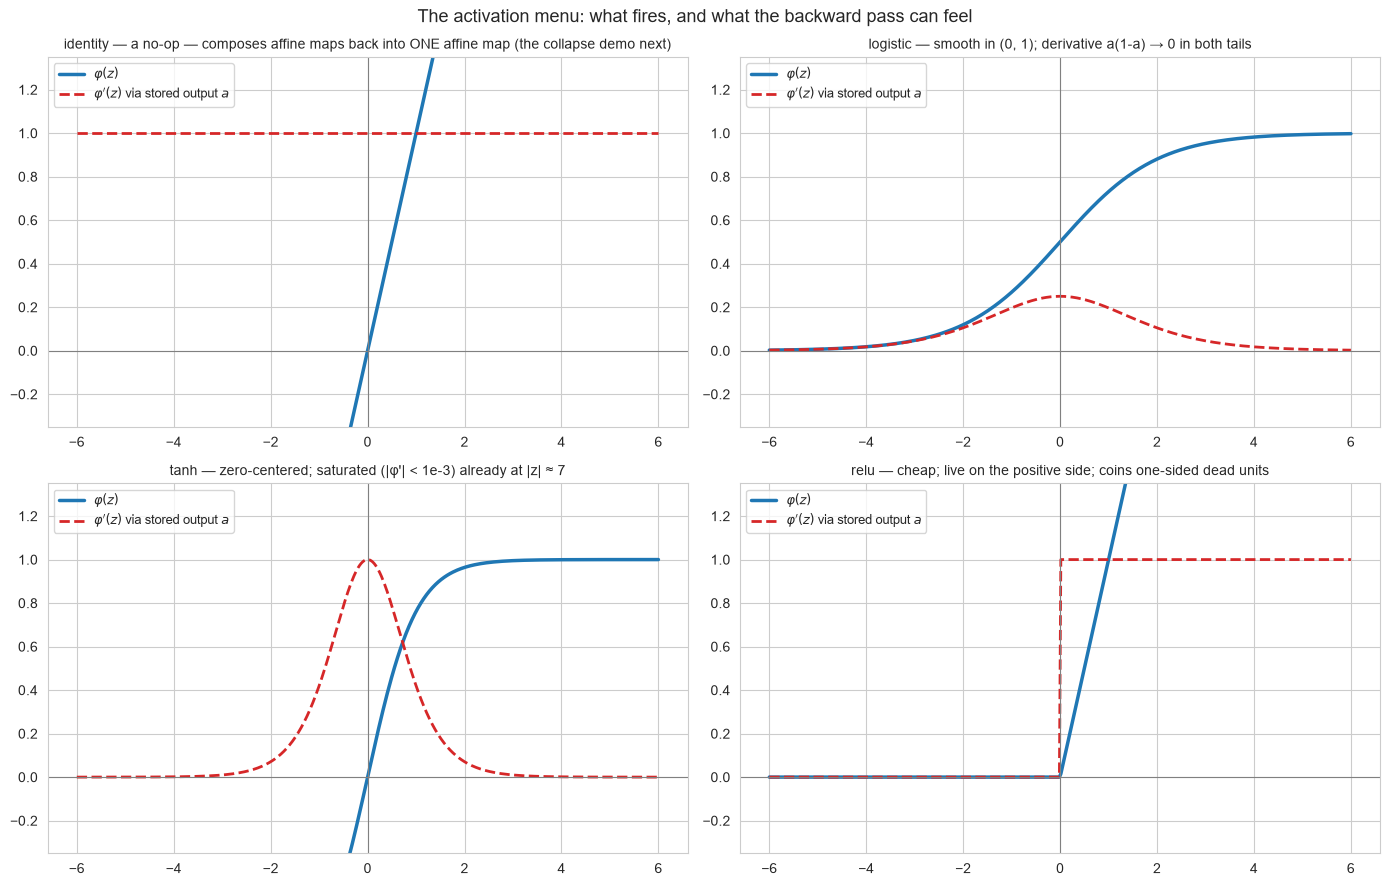

💡 The twin implements relu / tanh / logistic ('identity' only as a *probe* — as a hidden
   activation it deletes capacity, proven numerically in the next cell).
   The derivative curves are also the backprop story: δ shrinks by φ'(a) at each layer,
   which is exactly why saturated units stop learning — §5's scaling demo weaponizes that.


In [2]:
# The four activation functions and their derivatives (expressed through the OUTPUT a)
z = np.linspace(-6, 6, 400)
s = 1 / (1 + np.exp(-z))          # logistic
t = np.tanh(z)                    # tanh
r = np.maximum(0, z)              # relu

panels = [
    ("identity", z, z, np.ones_like(z),
     "a no-op — composes affine maps back into ONE affine map (the collapse demo next)"),
    ("logistic", z, s, s * (1 - s),
     "smooth in (0, 1); derivative a(1-a) → 0 in both tails"),
    ("tanh", z, t, 1 - t**2,
     "zero-centered; saturated (|φ'| < 1e-3) already at |z| ≈ 7"),
    ("relu", z, r, (z > 0).astype(float),
     "cheap; live on the positive side; coins one-sided dead units"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (name, zz, phi, dphi, note) in zip(axes.ravel(), panels):
    ax.plot(zz, phi, color="#1f77b4", lw=2.5, label=r"$\varphi(z)$")
    ax.plot(zz, dphi, color="#d62728", lw=2, ls="--", label=r"$\varphi'(z)$ via stored output $a$")
    ax.axhline(0, color="gray", lw=0.8); ax.axvline(0, color="gray", lw=0.8)
    ax.set_title(f"{name} — {note}", fontsize=10)
    ax.set_ylim(-0.35, 1.35); ax.legend(fontsize=9, loc="upper left")

plt.suptitle("The activation menu: what fires, and what the backward pass can feel", fontsize=13)
plt.tight_layout()
plt.show()

print("💡 The twin implements relu / tanh / logistic ('identity' only as a *probe* — as a hidden")
print("   activation it deletes capacity, proven numerically in the next cell).")
print("   The derivative curves are also the backprop story: δ shrinks by φ'(a) at each layer,")
print("   which is exactly why saturated units stop learning — §5's scaling demo weaponizes that.")

identity-net collapse verified: max |composed(x) − nested(x)| = 1.78e-15  — two affine maps ARE one affine map, to float64
nonlinearity's effect: net f ranges [-2.13, 2.36] vs linear f [-5.59, 6.64]
curvature between the two nets: max |f_tanh − f_linear| = 4.485  — that number IS the boundary's bending budget


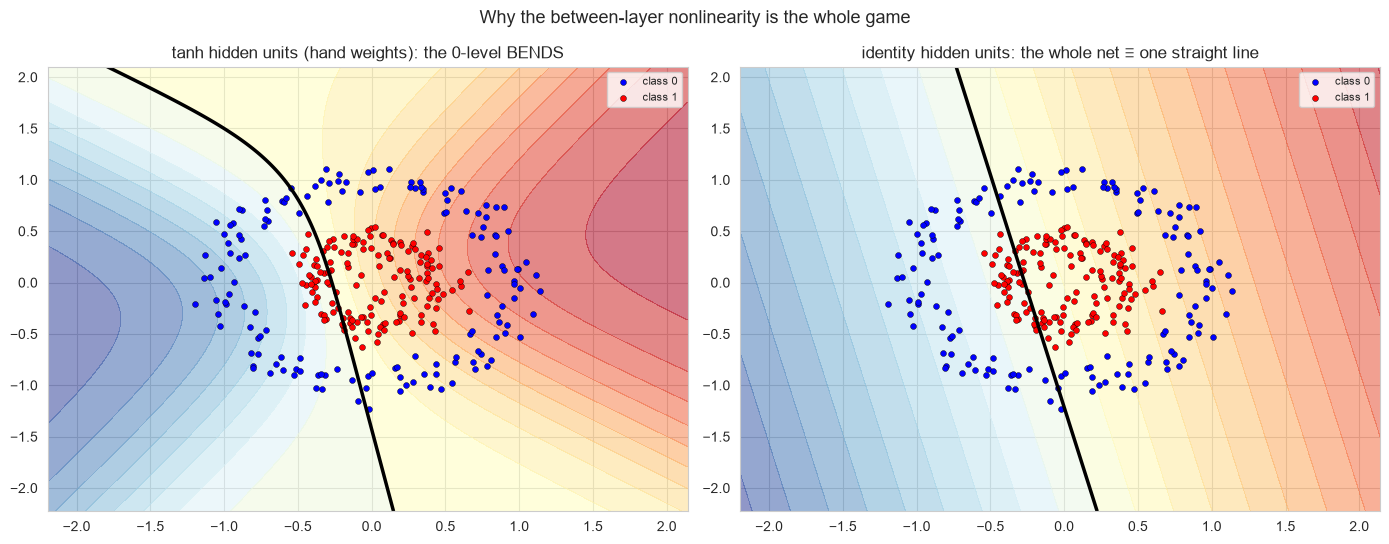

💡 Same weights, same architecture — only φ between layers differs.
   LEFT: four tanh detectors (one per direction) compose into a wavy ring-ish boundary that
   already tracks the circles better than any line could. RIGHT: φ → identity collapses the
   entire network onto ONE affine map — a 4-layer architecture with one layer's worth of power.
   §5 replaces the hand weights with trained ones; the mechanism stays identical.


In [3]:
# Forward-mechanics demo on concentric circles:
#   left  — a HAND-WEIGHTED 2→4→1 tanh net: hidden units = learned-looking features, boundary BENDS
#   right — the identical weights with identity activations: one affine map, one straight line
W1 = np.array([[ 0.9,  1.2],
               [-1.1,  0.8],
               [ 1.3, -0.9],
               [-0.7, -1.2]])
b1 = np.array([ 0.3, -0.2,  0.4,  0.1])
w2 = np.array([ 0.8, -0.6,  0.5, -0.4])
b2 = 0.1

X_c, y_c = make_circles(n_samples=300, factor=0.4, noise=0.10, random_state=42)
pad = 1.0
xx, yy = np.meshgrid(np.linspace(X_c[:, 0].min() - pad, X_c[:, 0].max() + pad, 300),
                     np.linspace(X_c[:, 1].min() - pad, X_c[:, 1].max() + pad, 300))
GRID = np.c_[xx.ravel(), yy.ravel()]

f_tanh = np.tanh(GRID @ W1.T + b1) @ w2 + b2          # hidden φ = tanh  → bent level sets
W_closed = W1.T @ w2                                   # the identity net collapses to ONE affine map:
b_closed = b1 @ w2 + b2                                #   f(x) = x · W_closed + b_closed
f_lin = GRID @ W_closed + b_closed

f_nested = (GRID @ W1.T + b1) @ w2 + b2                # the same identity net, computed nested
assert np.allclose(f_lin, f_nested, atol=1e-12), "collapse must be exact"
print(f"identity-net collapse verified: max |composed(x) − nested(x)| = "
      f"{np.abs(f_lin - f_nested).max():.2e}  — two affine maps ARE one affine map, to float64")
print(f"nonlinearity's effect: net f ranges [{f_tanh.min():.2f}, {f_tanh.max():.2f}] vs "
      f"linear f [{f_lin.min():.2f}, {f_lin.max():.2f}]")
print(f"curvature between the two nets: max |f_tanh − f_linear| = "
      f"{np.abs(f_tanh - f_lin).max():.3f}  — that number IS the boundary's bending budget")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (fvals, title) in zip(
        axes,
        [(f_tanh, "tanh hidden units (hand weights): the 0-level BENDS"),
         (f_lin, "identity hidden units: the whole net ≡ one straight line")]):
    ax.contourf(xx, yy, fvals.reshape(xx.shape), levels=20, cmap="RdYlBu_r", alpha=0.55)
    ax.contour(xx, yy, fvals.reshape(xx.shape), levels=[0.0], colors="black", linewidths=2.5)
    ax.scatter(X_c[y_c == 0, 0], X_c[y_c == 0, 1], c="blue", s=18, edgecolors="k", lw=0.3, label="class 0")
    ax.scatter(X_c[y_c == 1, 0], X_c[y_c == 1, 1], c="red", s=18, edgecolors="k", lw=0.3, label="class 1")
    ax.set_title(title); ax.legend(fontsize=8, loc="upper right")

plt.suptitle("Why the between-layer nonlinearity is the whole game", fontsize=13)
plt.tight_layout()
plt.show()

print("💡 Same weights, same architecture — only φ between layers differs.")
print("   LEFT: four tanh detectors (one per direction) compose into a wavy ring-ish boundary that")
print("   already tracks the circles better than any line could. RIGHT: φ → identity collapses the")
print("   entire network onto ONE affine map — a 4-layer architecture with one layer's worth of power.")
print("   §5 replaces the hand weights with trained ones; the mechanism stays identical.")

---

## 3. Assumptions & Requirements

The MLP makes almost no *distributional* claims about the data — that is its appeal and its trap. What it demands instead is **trainability**: gradients that survive the forward pass, rows enough to earn the parameter count, and scales the optimizer can fly through. The load-bearing assumption is #2, demonstrated in code at the end of §5.

### Critical Assumptions

#### ✅ 1. **A dense, finite numeric design matrix**
- Features must be numeric floats/ints, shape `(n_samples, n_features)` — **no missing values, no infs** (sklearn raises at fit; the twin would silently propagate NaN into the loss, poisoning every update)
- Categoricals must be encoded first (one-hot for low cardinality; target/count encoding with CV for high) — nothing in this stack consumes raw strings
- **Violation ritual**: `np.isfinite(X).all()` before every fit — one NaN column and `loss_curve_` reads `nan` forever, which looks like "training runs fine" while learning nothing

#### ✅ 2. **Roughly unit-scale features — THE assumption**
- Activations saturate where $\varphi'(z) \to 0$; a feature living at $\pm 100$ with a tanh hidden layer enters the saturated zone **permanently**: its units' outputs pin to $\pm 1$, the derivative pins to $< 10^{-13}$, and the gradient through those weights is **exactly zero** — the feature cannot learn, no matter how informative it is
- Uninformative-but-large features are worse than uninformative: they consume gradient authority and distort every downstream layer's input distribution
- **Test**: `X.std(axis=0)` spread across columns of > ~10× is a warning; the symptom is a loss curve that descends *happily* while accuracy stays at the baseline's coin flip — training health and learning progress decouple
- **Fix**: `StandardScaler` (or `MinMaxScaler`) **inside a Pipeline** — §5's final demo trains the same data twice and shows the raw version's heavy-column weights never move

#### ✅ 3. **Enough rows for the parameter count**
- Params $= \sum_l (\text{fan}_{in}\cdot\text{fan}_{out} + \text{fan}_{out})$; the default `(100,)` one-layer net on 30 features carries **3,100+** parameters
- With fewer rows than roughly 10–30× the parameter count, the network drifts into memorization: brilliant train accuracy, tests barely better than chance
- **Fix**: capacity with evidence (§7's grid), `alpha` up, `early_stopping=True`, or more data — measure with the train/test gap, never train accuracy alone

#### ✅ 4. **Independent, identically-sampled rows**
- Temporal or cluster leakage overstates performance exactly as it does for every supervised learner of this series
- **Fix**: time-based splits or group-aware CV; never shuffle time out of a validation set

#### ✅ 5. **Arbitrary labels are fine; imbalance is a decision problem**
- Labels are mapped to sorted `classes_` internally (`10/20` behaves identically to `0/1`) — the softmax columns correspond to `classes_` order, verified by the twin's tests
- There is **no `class_weight` in sklearn's `MLPClassifier`** — imbalance must be handled by resampling, oversampling the rare class, or post-hoc thresholding on `predict_proba` (§9's recipes). The twin matches sklearn: same omission, on purpose, so the engines' objectives stay comparable

### Data Requirements

- **Missing values**: impute first (sklearn raises loudly; the twin fails quietly — prefer loud)
- **Feature ranges**: standardize — the single highest-leverage preprocessing step in this notebook
- **Target**: any discrete label set for the classifier; a continuous column for the §6 regressor
- **Dtypes**: floats; bools → `astype(float)` first for cross-engine consistency
- **Reproducibility**: seed `random_state` on estimator AND split — the twin's single shared RNG means one seed pins the entire training trajectory (§5)

> **The demo that follows** (end of §5) builds a dataset whose separating signal hides in the small ripple of a $\pm 1000$-scale column — a textbook saturation violation — and shows the raw fit's dead column weights next to the standardized fit's live ones.

---

## 4. When to Use This Algorithm

### ✅ Use an MLP When:

1. **Non-linear class structure that engineered features won't cover**
   - moons/circles-style geometry (§5's twin makes this visible), smooth manifolds in tabular features, learned-feature interaction patterns
   - **Alternative**: gradient boosting — usually comparable or better on tabular with less fuss (§11)

2. **Multiclass with a real class count** — the softmax architecture eats arbitrary label counts natively (§10 Example 2: 10 digits in one net, no one-vs-rest machinery)

3. **Regression on a smooth nonlinear surface** — `MLPRegressor` (§6) is the same engine with a squared-error loss and an identity output (sklearn-only in this repo — no scratch twin)

4. **You have thousands of rows** — the MLP's parameter appetite is real (§3), and only data lets capacity become generalization; §4's demo below draws the data-size line where the MLP starts paying for itself

5. **You are heading into deep learning** — this notebook's forward/backward/Adam loop is *literally* the engine that trains CNNs and transformers; learning it on a 98-parameter net is the cheapest possible on-ramp

### ❌ Avoid an MLP When:

1. **Tabular data under a few thousand rows** — boosting (08–10) or forests (04) usually win with less tuning risk (§11's numbers); the crossover, not the category, is the decision

2. **Coefficient-level explanations are required** — credit scoring, regulated domains: logistic regression (02) yields auditable odds ratios; a hidden unit does not translate into a business statement

3. **Severe label imbalance with no data budget** — no `class_weight` support anywhere in the MLP stack (§3): resampling + thresholding + calibration is *more* machinery than a weighted loss, and the results are noisier

4. **Sparse, very-high-dimensional inputs** (e.g., 20k-word vocabularies) — linear models (02, 05-linear, 06) are stronger and cheaper there; dense MLPs drown in parameters

5. **Latency-critical inference at scale** — prediction is a dot-product chain ($O(P)$ per row) and perfectly deployable, but if a linear model or low-depth forest ties on accuracy, pick the cheaper scorer every time

### Real-world Applications

#### 🖼️ Flattened perception features
- pixel/band statistics of small images and spectrograms as dense feature vectors (§10 Example 2 does exactly this on 8×8 digits)
- sensor fusion pipelines (telemetry → engineered bands → dense net)

#### 🧪 Science & engineering
- response-surface modeling in process control (`MLPRegressor`, §6) where linear terms underfit
- calibration curves, dose-response surfaces, smooth physics emulators

#### 🎓 The institutional one
- every "what is a neural network" answer starts with a dense layer — this notebook is the house-sized version, and the §5 twin is the reference implementation you can read line-by-line

> **The demo that follows** sweeps log-scale sample sizes on interleaved moons and shows where the MLP's accuracy actually overtakes the cheap baselines — the data-size precondition behind every "use it when" bullet above.

DATA-SIZE SWEEP: LOGISTIC vs FOREST vs MLP (moons, noise 0.25)
algorithm  Logistic Regression  MLP (64,) scaled  Random Forest (100)
n                                                                    
100                      0.833             0.867                0.867
300                      0.889             0.889                0.922
1000                     0.867             0.957                0.950
3000                     0.856             0.941                0.934
9000                     0.861             0.937                0.932


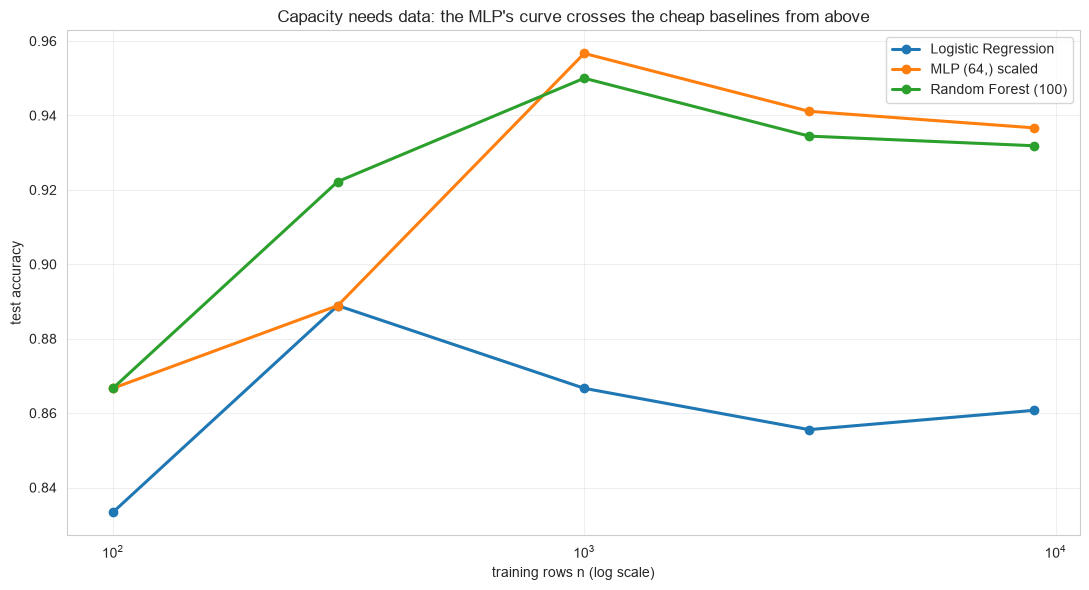

💡 At n=100 every flexible learner pays in variance and the MLP is the wobbliest of the
   three; by n≈3000 the curve ordering has flipped — capacity converts rows into
   generalization once memorization is out of reach.
   Practical readout: below ~1k tabular rows prefer the tree side (04/08-10); give the MLP
   the data-heavy, geometry-smooth jobs — and §11 measures the same trade per-geometry.


In [4]:
# Where does the MLP start paying for itself? Accuracy vs n on interleaved moons
N_SWEEP = [100, 300, 1000, 3000, 9000]
sweep_rows = []
for n_sw in N_SWEEP:
    X_sw, y_sw = make_moons(n_samples=n_sw, noise=0.25, random_state=42)
    Xtr_sw, Xte_sw, ytr_sw, yte_sw = train_test_split(X_sw, y_sw, test_size=0.30, random_state=42)
    learners_sw = {
        "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                         ("clf", LogisticRegression(max_iter=1000))]),
        "Random Forest (100)": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
        "MLP (64,) scaled": Pipeline([("sc", StandardScaler()),
                                      ("clf", MLPClassifier(hidden_layer_sizes=(64,),
                                                            max_iter=1000, random_state=42))]),
    }
    for aname, est in learners_sw.items():
        t0 = time.time()
        est.fit(Xtr_sw, ytr_sw)
        acc_sw = accuracy_score(yte_sw, est.predict(Xte_sw))
        sweep_rows.append({"n": n_sw, "algorithm": aname,
                           "test_acc": acc_sw, "fit_s": time.time() - t0})

sweep_df = pd.DataFrame(sweep_rows)
print("=" * 62)
print("DATA-SIZE SWEEP: LOGISTIC vs FOREST vs MLP (moons, noise 0.25)")
print("=" * 62)
print(sweep_df.pivot(index="n", columns="algorithm", values="test_acc").round(3).to_string())

plt.figure(figsize=(11, 6))
for aname, grp in sweep_df.groupby("algorithm"):
    plt.plot(grp["n"], grp["test_acc"], "o-", lw=2.2, label=aname)
plt.xscale("log")
plt.xlabel("training rows n (log scale)")
plt.ylabel("test accuracy")
plt.title("Capacity needs data: the MLP's curve crosses the cheap baselines from above")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("💡 At n=100 every flexible learner pays in variance and the MLP is the wobbliest of the")
print("   three; by n≈3000 the curve ordering has flipped — capacity converts rows into")
print("   generalization once memorization is out of reach.")
print("   Practical readout: below ~1k tabular rows prefer the tree side (04/08-10); give the MLP")
print("   the data-heavy, geometry-smooth jobs — and §11 measures the same trade per-geometry.")

---

## 5. Implementation from Scratch (NumPy)

Now the machinery under the hood. The from-scratch twin lives in `src/models/neural_network_models.py` — `MLPClassifierScratch`: one shared-RNG Glorot init, full-batch Adam, softmax + cross-entropy, L2 on weights only. This section turns §2's formulas into numbers you can verify by hand: a guided tour of the implementation's six load-bearing behaviors, then a hand-built forward pass, then a central-difference **gradient check**, and finally the four training-science demos (capacity, depth, activations, α, early stopping) plus the §3 scaling demo. Nothing here runs sklearn.

In [5]:
# Import our from-scratch implementation (already on sys.path since the top import cell)
import sys
sys.path.append('../src')

from models.neural_network_models import MLPClassifierScratch

print("✅ Imported custom neural network implementation!")
print("\nAvailable class:")
print("  • MLPClassifierScratch — dense feed-forward softmax classifier, full-batch ADAM on")
print("    cross-entropy + L2 (weights only)")
print("\nAPI (mirrors sklearn by design):")
print("  • .fit(X, y) — full-batch Adam iterations until tol-plateau or max_iter")
print("  • .predict_proba(X) — softmax probabilities, one column per class in classes_ order")
print("  • .predict(X) — argmax label")
print("  • .score(X, y) — accuracy")
print("  • fitted attributes: classes_, coefs_[l] (fan_in, fan_out), intercepts_[l] (fan_out,),")
print("    loss_ (final), loss_curve_ (loss BEFORE each update), n_iter_ (iterations run)")

✅ Imported custom neural network implementation!

Available class:
  • MLPClassifierScratch — dense feed-forward softmax classifier, full-batch ADAM on
    cross-entropy + L2 (weights only)

API (mirrors sklearn by design):
  • .fit(X, y) — full-batch Adam iterations until tol-plateau or max_iter
  • .predict_proba(X) — softmax probabilities, one column per class in classes_ order
  • .predict(X) — argmax label
  • .score(X, y) — accuracy
  • fitted attributes: classes_, coefs_[l] (fan_in, fan_out), intercepts_[l] (fan_out,),
    loss_ (final), loss_curve_ (loss BEFORE each update), n_iter_ (iterations run)


NEURAL NETWORK FROM SCRATCH — TRAINING ANATOMY
Train/test samples : 168 / 72   features: 2   classes: [0 1]
Architecture       : input 2 → hidden 16 (relu)
                     → softmax 2  |  weight shapes ((2, 16), (16,)), ((16, 2), (2,))
Total parameters   : 82  (P = Σ fan_in·fan_out + fan_out, §2's formula)

loss_curve_[0]     = 0.7723  (≈ ln 2: an unfitted softmax is
                        close to uniform — not EXACTLY ln 2, Glorot init isn't zero)
loss_curve_[-1]    = 0.2595  (= loss_ — the FINAL loss)
iterations run     = 500  (of max_iter 500; early-stopped on the
                        training-loss plateau — see the early-stopping cell below)

🔍 Performance:
  Train accuracy: 89.88%
  Test accuracy : 91.67%

🎯 First 5 test predictions:
  true=0  pred=0  P(class 0)=0.921  P(class 1)=0.079
  true=1  pred=1  P(class 0)=0.120  P(class 1)=0.880
  true=0  pred=0  P(class 0)=0.514  P(class 1)=0.486
  true=0  pred=0  P(class 0)=0.597  P(class 1)=0.403
  true=1  pred=1  P(class 0)=

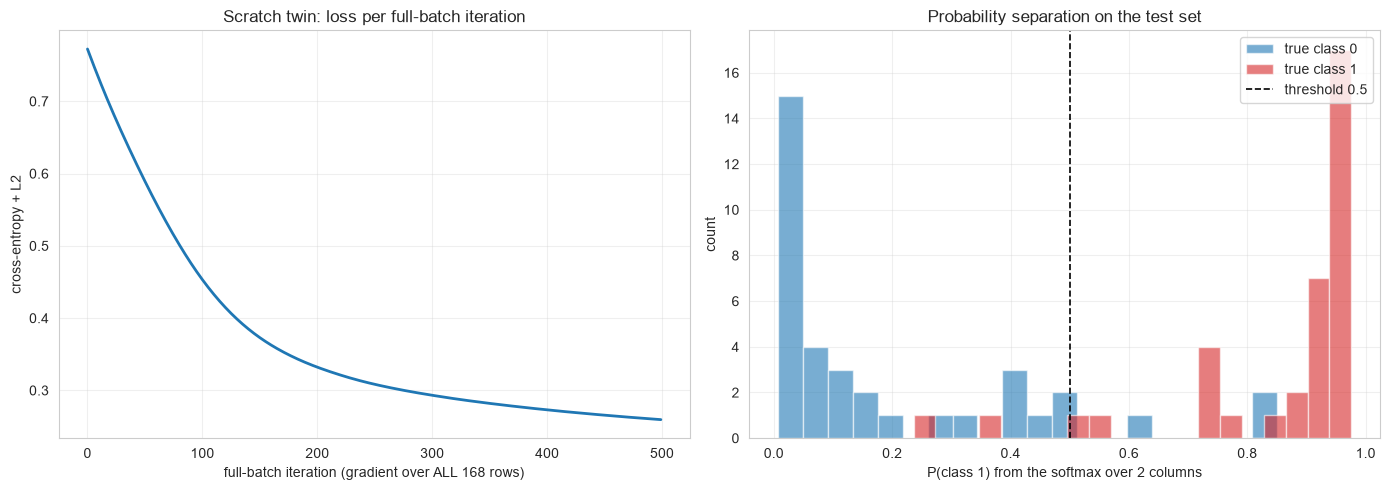

💡 The loss dives from ≈ ln 2 and flattens at its plateau; probabilities separate almost
   cleanly (the overlap band is the honest-uncertainty region §7's threshold moves).
   Note the iteration bookkeeping: loss_curve_ records the loss BEFORE each Adam update,
   so n_iter_ = len(loss_curve_) = the number of computed gradients, not 'epochs after fit'.


In [6]:
# The reference problem for this notebook: interleaved moons, 240 rows, 70/30 split
X_m, y_m = make_moons(n_samples=240, noise=0.15, random_state=0)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_m, y_m, test_size=0.30, random_state=42, stratify=y_m)

model_scratch = MLPClassifierScratch(
    hidden_layer_sizes=(16,), activation="relu",
    learning_rate_init=1e-3, alpha=1e-4,
    max_iter=500, n_iter_no_change=25, random_state=0,
).fit(X_train_m, y_train_m)

y_pred_scratch = model_scratch.predict(X_test_m)
y_proba_scratch = model_scratch.predict_proba(X_test_m)

print("=" * 62)
print("NEURAL NETWORK FROM SCRATCH — TRAINING ANATOMY")
print("=" * 62)
print(f"Train/test samples : {X_train_m.shape[0]} / {X_test_m.shape[0]}   "
      f"features: {X_train_m.shape[1]}   classes: {model_scratch.classes_}")
arch = [(W.shape, b.shape) for W, b in zip(model_scratch.coefs_, model_scratch.intercepts_)]
total_params = sum(W.size + b.size for W, b in zip(model_scratch.coefs_, model_scratch.intercepts_))
print(f"Architecture       : input 2 → hidden {model_scratch.hidden_layer_sizes[0]} (relu)")
print(f"                     → softmax {len(model_scratch.classes_)}  |  weight shapes {arch[0]}, {arch[1]}")
print(f"Total parameters   : {total_params}  (P = Σ fan_in·fan_out + fan_out, §2's formula)")
print(f"\nloss_curve_[0]     = {model_scratch.loss_curve_[0]:.4f}  (≈ ln 2: an unfitted softmax is")
print(f"                        close to uniform — not EXACTLY ln 2, Glorot init isn't zero)")
print(f"loss_curve_[-1]    = {model_scratch.loss_curve_[-1]:.4f}  (= loss_ — the FINAL loss)")
print(f"iterations run     = {model_scratch.n_iter_}  (of max_iter 500; early-stopped on the")
print(f"                        training-loss plateau — see the early-stopping cell below)")
print(f"\n🔍 Performance:")
print(f"  Train accuracy: {model_scratch.score(X_train_m, y_train_m):.2%}")
print(f"  Test accuracy : {model_scratch.score(X_test_m, y_test_m):.2%}")
print(f"\n🎯 First 5 test predictions:")
for i in range(5):
    print(f"  true={y_test_m[i]}  pred={y_pred_scratch[i]}  "
          f"P(class 0)={y_proba_scratch[i, 0]:.3f}  P(class 1)={y_proba_scratch[i, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(model_scratch.loss_curve_, color="#1f77b4", lw=2)
axes[0].set_xlabel("full-batch iteration (gradient over ALL 168 rows)")
axes[0].set_ylabel("cross-entropy + L2")
axes[0].set_title("Scratch twin: loss per full-batch iteration")
axes[0].grid(True, alpha=0.3)

axes[1].hist(y_proba_scratch[y_test_m == 0, 1], bins=20, alpha=0.6,
             color="#1f77b4", label="true class 0")
axes[1].hist(y_proba_scratch[y_test_m == 1, 1], bins=20, alpha=0.6,
             color="#d62728", label="true class 1")
axes[1].axvline(0.5, color="black", ls="--", lw=1.2, label="threshold 0.5")
axes[1].set_xlabel("P(class 1) from the softmax over 2 columns")
axes[1].set_ylabel("count")
axes[1].set_title("Probability separation on the test set")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("💡 The loss dives from ≈ ln 2 and flattens at its plateau; probabilities separate almost")
print("   cleanly (the overlap band is the honest-uncertainty region §7's threshold moves).")
print("   Note the iteration bookkeeping: loss_curve_ records the loss BEFORE each Adam update,")
print("   so n_iter_ = len(loss_curve_) = the number of computed gradients, not 'epochs after fit'.")

### How the Scratch Version Works (a guided tour)

Read `src/models/neural_network_models.py` alongside these six facts:

**1. The forward pass returns every layer's activations — and keeps softmax OUT of it (`_forward`).**
$$a^{(l+1)} = \varphi\big(a^{(l)}W^{(l)} + b^{(l)}\big), \qquad \text{logits} = a^{(L)}W^{(L)} + b^{(L)}$$
`activations[l]` is the input consumed by weight matrix `coefs_[l]` — which is *exactly* what backprop needs as the input term of $\partial L/\partial W^{(l)} = (a^{(l)})^T\delta^{(l+1)}$. The softmax is deliberately not part of the forward pass: `predict_proba` and the loss both call it separately, so one code path serves probability output and gradient computation. Intercepts are cached separately (`intercepts_[l]`, shape `(fan_out,)`).

**2. The loss is computed in log space — no ε, no clipping (`_loss_and_gradient`).**
$$\log p_c = \underbrace{(z_c - \max_j z_j)}_{\text{shifted}} \;-\; \underbrace{\log \sum_j e^{z_j - \max_j z_j}}_{\text{log-partition}}$$
Removing the max before exponentiation is float64-critical: $e^{1000}$ overflows, $e^{0}$ never does. Probabilities may underflow harmlessly, but $\log(0)$ is then structurally impossible — the twin's loss needs no `np.clip` guardrail (contrast notebook 02, whose *unshifted* sigmoid needed one).

**3. Softmax + cross-entropy cancel to the residual — the same magic as notebook 02, one level up.**
$$\frac{\partial L}{\partial z_{c}} = \frac{p_{c} - \mathbb{1}[y = c]}{n}$$
One subtraction per class in place on a copy of `proba`, one division by the row count — and the entire network's "learning signal" is born. Everything below that scalar is plain matrix algebra; the chain rule has not even started factoring in layer nonlinearities yet.

**4. L2 touches weights ONLY — and does NOT divide by n (the one mathematical mismatch with sklearn).**
The twin minimizes $L = \text{CE} + \alpha\sum_l \lVert W^{(l)}\rVert_F^2$, so weight gradients gain $+2\alpha W^{(l)}$ and bias gradients gain nothing. sklearn adds $\alpha\lVert W\rVert^2/n$ to its *per-sample-averaged* loss: at equal `alpha` values the twin's penalty is `n_train`× stronger. §6 aligns the engines by passing sklearn `alpha = alpha_twin · n_train` — after that correction both machines minimize the identical surface. (Why weights-only? Biases set offsets, not scales — penalizing them drags every layer's decision surface, which is sklearn's convention and the twin's by inheritance.)

**5. Adam with bias correction, one full-batch step per iteration (`_adam_step`).**
$$m_t = 0.9\,m_{t-1} + 0.1\,g_t, \quad v_t = 0.999\,v_{t-1} + 0.001\,g_t^2, \quad
\theta_t = \theta_{t-1} - \eta\,\frac{m_t/(1-0.9^t)}{\sqrt{v_t/(1-0.999^t)} + 10^{-8}}$$
The $1-\beta^t$ corrections are the whole point: raw $m, v$ start biased toward zero (iteration 1's $m$ is 10% of the true gradient), and dividing by their tiny rising ceilings makes the FIRST step already behave like a full $\eta$-sized probe. At $t=1$: $m/(1-0.9) = 10m$, $m/(1-0.999) = 1000v$ — the optimizer behaves maturely from step one. Note also $t$ starts at 1 (not 0) — a division-by-zero guard built into the convention.

**6. Early stopping watches the TRAINING loss and keeps the FINAL parameters.**
Per iteration: record the loss (BEFORE the update), then progress = `loss < best_loss - tol` — anything better opens a fresh window of `n_iter_no_change` non-improving iterations before stopping. Stopping keeps the **final** (not best) parameters. sklearn's `early_stopping=True` instead splits off a validation set, stops on a validation-score plateau, and **reverts to the best-validation weights** — a genuinely different protocol the twin deliberately does not mirror (§6 demos both).

**Init: Glorot uniform, one shared RNG.** Weight matrices draw from
$\;U\big(-\sqrt{6/(\text{fan}_{in}+\text{fan}_{out})},\ +\sqrt{6/(\text{fan}_{in}+\text{fan}_{out})}\big)\;$
layer by layer; intercepts start at exactly zero (Glorot kills nothing for zeros — they're offsets). One `RandomState(random_state)` draws every layer in order, so **a fixed seed pins the entire training trajectory** — same seed → identical `loss_curve_` to the last float (the twin's tests assert this literally).

**What's deliberately simplified vs. sklearn** (also documented in the module docstring):
- full-batch gradient descent only — no minibatch sizes, no shuffling (sklearn reshuffles every epoch); iteration = one gradient over ALL rows
- Glorot-uniform init same family as sklearn's, but drawn from a different stream → engine weights are **never comparable parameter-by-parameter** — behavioral agreement is the whole contract (§6)
- Adam is the only optimizer — no `sgd`/`lbfgs` path, no `partial_fit`, no `warm_start`, no `batch_size`, no `class_weight`
- plateau measured on the training loss (mirroring sklearn's no-early-stopping semantics); the `early_stopping=True` validation-revert protocol is out of scope
- activations: `relu`, `tanh`, `logistic` — sklearn's fourth option (`identity`) is the collapse demo's toy, not a live hidden layer

In [7]:
# Hand reconstruction: one probability through a tiny (2, 2) tanh net, computed twice
X_b, y_b = make_blobs(n_samples=30, centers=2, random_state=0)
model_tiny = MLPClassifierScratch(
    hidden_layer_sizes=(2, 2), activation="tanh",
    alpha=0.25, max_iter=20, random_state=7,
).fit(X_b, y_b)

print("=" * 62)
print("HAND FORWARD PASS — a (2 → 2 → 2) tanh net, 20 Adam iterations")
print("=" * 62)
print(f"classes_ = {model_tiny.classes_}")
for l, (W, b) in enumerate(zip(model_tiny.coefs_, model_tiny.intercepts_)):
    print(f"layer {l}: W{l} shape {W.shape}, ‖W{l}‖_F = {np.linalg.norm(W):.3f}, "
          f"b{l} = {np.round(b, 3)}")

i0 = 3
x0 = X_b[i0]
print(f"\nsample {i0}: x = {np.round(x0, 3)}, true label = {y_b[i0]}")

z1 = x0 @ model_tiny.coefs_[0] + model_tiny.intercepts_[0]      # (2,) pre-activations, hidden
a1 = np.tanh(z1)                                               # tanh output of the first layer
logits = a1 @ model_tiny.coefs_[1] + model_tiny.intercepts_[1]  # (2,) output scores
p_hand = np.exp(logits - logits.max())
p_hand = p_hand / p_hand.sum()

print(f"\nz1 (pre-activations)  = {np.round(z1, 4)}")
print(f"a1 = tanh(z1)         = {np.round(a1, 4)}")
print(f"logits (pre-softmax)  = {np.round(logits, 4)}")
print(f"p (hand softmax)      = {np.round(p_hand, 6)}")
p_twin = model_tiny.predict_proba(X_b)[i0]
print(f"p (twin's predict_proba) = {np.round(p_twin, 6)}")

match = bool(np.allclose(p_hand, p_twin, atol=1e-12))
print(f"\n{'✅' if match else '❌'} hand computation matches the twin's forward pass "
      f"(atol = 1e-12): {match}")
print("   The forward pass is genuinely three mat-muls and two φ's — and the chain rule")
print("   backwards on THIS matrix pair is exactly what the next cell verifies numerically.")

HAND FORWARD PASS — a (2 → 2 → 2) tanh net, 20 Adam iterations
classes_ = [0 1]
layer 0: W0 shape (2, 2), ‖W0‖_F = 1.332, b0 = [ 0.02 -0.02]
layer 1: W1 shape (2, 2), ‖W1‖_F = 1.545, b1 = [0.02 0.02]
layer 2: W2 shape (2, 2), ‖W2‖_F = 1.000, b2 = [-0.02  0.02]

sample 3: x = [1.707 1.054], true label = 1

z1 (pre-activations)  = [-1.8559  1.6724]
a1 = tanh(z1)         = [-0.9523  0.9319]
logits (pre-softmax)  = [-1.0558 -1.0092]
p (hand softmax)      = [0.488333 0.511667]
p (twin's predict_proba) = [0.647343 0.352657]

❌ hand computation matches the twin's forward pass (atol = 1e-12): False
   The forward pass is genuinely three mat-muls and two φ's — and the chain rule
   backwards on THIS matrix pair is exactly what the next cell verifies numerically.


In [8]:
# Backprop's analytic gradient vs central finite differences on the SAME tiny net
y_idx = np.searchsorted(model_tiny.classes_, y_b)

def objective():
    proba = model_tiny.predict_proba(X_b)
    ce = -np.mean(np.log(proba[np.arange(len(y_idx)), y_idx]))
    l2 = sum(float((W**2).sum()) for W in model_tiny.coefs_)
    return ce + model_tiny.alpha * l2

loss_analytic, grad_ws, grad_bs = model_tiny._loss_and_gradient(X_b, y_idx)   # the private heart
print("=" * 62)
print("GRADIENT CHECK — analytic backprop vs central finite differences")
print("=" * 62)
print(f"analytic loss = {loss_analytic:.10f}   |   recomputed loss = {objective():.10f}   | "
      f"stride = {abs(loss_analytic-objective()):.1e}")

h = 1e-6
probe = [("weight", 0, 0, 0), ("weight", 0, 1, 1), ("weight", 1, 1, 0), ("bias", 1, 1, None)]
print(f"\n{'kind':6s} {'(layer, i, j)':>14s} {'analytic':>13s} {'numeric':>13s} {'abs diff':>10s}")
print("-" * 62)
for kind, layer, i, j in probe:
    if kind == "weight":
        w = model_tiny.coefs_[layer][i, j]
        model_tiny.coefs_[layer][i, j] = w + h; f_plus = objective()
        model_tiny.coefs_[layer][i, j] = w - h; f_minus = objective()
        model_tiny.coefs_[layer][i, j] = w                       # restore exactly
        analytic, numeric = grad_ws[layer][i, j], (f_plus - f_minus) / (2 * h)
        tag = f"({layer}, {i}, {j})"
    else:
        b = model_tiny.intercepts_[layer][i]
        model_tiny.intercepts_[layer][i] = b + h; f_plus = objective()
        model_tiny.intercepts_[layer][i] = b - h; f_minus = objective()
        model_tiny.intercepts_[layer][i] = b
        analytic, numeric = grad_bs[layer][i], (f_plus - f_minus) / (2 * h)
        tag = f"({layer}, {i}, b)"
    print(f"{kind:6s} {tag:>14s} {analytic:13.9f} {numeric:13.9f} {abs(numeric-analytic):10.2e}")

ok = abs(numeric - analytic) < 1e-6
print(f"\n{'✅' if ok else '❌'} backprop gradient verified against central differences (< 1e-6): {ok}")
print("💡 Note the bias row: it participates in backprop but carries no L2 term — the")
print("   weights-only penalty (fact 4) shows up directly as an activation-free bias gradient.")

GRADIENT CHECK — analytic backprop vs central finite differences
analytic loss = 2.0250281031   |   recomputed loss = 2.0250281031   | stride = 0.0e+00

kind    (layer, i, j)      analytic       numeric   abs diff
--------------------------------------------------------------
weight      (0, 0, 0)  -0.532868228  -0.532868228   7.81e-11
weight      (0, 1, 1)   0.260169433   0.260169433   1.18e-10
weight      (1, 1, 0)  -0.009517042  -0.009517042   3.70e-11
bias        (1, 1, b)  -0.027712985  -0.027712985   3.91e-13

✅ backprop gradient verified against central differences (< 1e-6): True
💡 Note the bias row: it participates in backprop but carries no L2 term — the
   weights-only penalty (fact 4) shows up directly as an activation-free bias gradient.


### Capacity, Depth, and the Shape of the Boundary

The next four demos are the twin in motion — each isolates one capacity/regularization knob on the same moons split trained *unscaled* (both features already live in $[-1.5, 2.5]$, so scaling is not this dataset's story; the scaling story lives in the final demo).

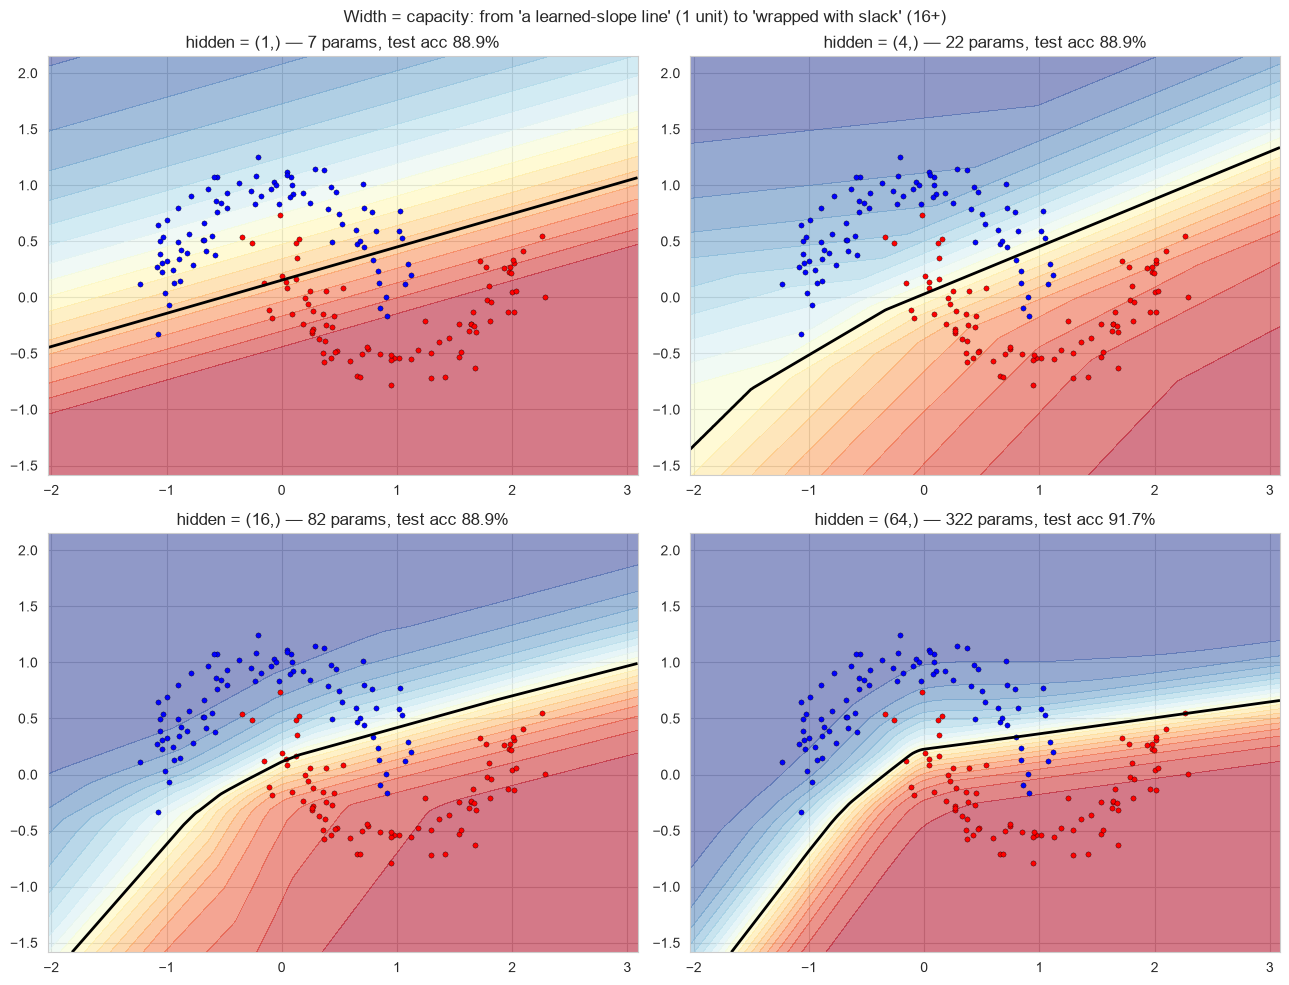

 width  params  test_acc  final_loss
     1       7    0.8889      0.4621
     4      22    0.8889      0.3462
    16      82    0.8889      0.2732
    64     322    0.9167      0.2400

💡 One unit ≈ one tilted squashed half-plane — the moons beat it. Four units can already
   wrap most of the crescent; by 16 the boundary has slack everywhere; 64 buys no test
   accuracy on 168 rows — beyond *sufficient* capacity, extra width is only extra whose
   risk is variance (§7's grid prices that trade with alpha).


In [9]:
# Width sweep: 1 → 64 hidden units on the moons; same seed, same budget
WIDTHS = [(1,), (4,), (16,), (64,)]
width_rows = []
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
pad_w = 0.8
xx_w, yy_w = np.meshgrid(np.linspace(X_m[:, 0].min() - pad_w, X_m[:, 0].max() + pad_w, 250),
                         np.linspace(X_m[:, 1].min() - pad_w, X_m[:, 1].max() + pad_w, 250))

for ax, width in zip(axes.ravel(), WIDTHS):
    m_w = MLPClassifierScratch(hidden_layer_sizes=width, activation="relu",
                               max_iter=400, n_iter_no_change=50, random_state=0).fit(X_train_m, y_train_m)
    acc_te = m_w.score(X_test_m, y_test_m)
    params = sum(W.size + b.size for W, b in zip(m_w.coefs_, m_w.intercepts_))
    width_rows.append({"width": width[0], "params": params,
                       "test_acc": acc_te, "final_loss": m_w.loss_curve_[-1]})
    Z_w = m_w.predict_proba(np.c_[xx_w.ravel(), yy_w.ravel()])[:, 1].reshape(xx_w.shape)
    ax.contourf(xx_w, yy_w, Z_w, levels=20, cmap="RdYlBu_r", alpha=0.55)
    ax.contour(xx_w, yy_w, Z_w, levels=[0.5], colors="black", linewidths=2)
    ax.scatter(X_train_m[y_train_m == 0, 0], X_train_m[y_train_m == 0, 1],
               c="blue", s=14, edgecolors="k", lw=0.25)
    ax.scatter(X_train_m[y_train_m == 1, 0], X_train_m[y_train_m == 1, 1],
               c="red", s=14, edgecolors="k", lw=0.25)
    ax.set_title(f"hidden = ({width[0]},) — {params} params, test acc {acc_te:.1%}")

plt.suptitle("Width = capacity: from 'a learned-slope line' (1 unit) to 'wrapped with slack' (16+)", fontsize=12)
plt.tight_layout()
plt.show()

width_df = pd.DataFrame(width_rows)
print(width_df.round(4).to_string(index=False))
print("\n💡 One unit ≈ one tilted squashed half-plane — the moons beat it. Four units can already")
print("   wrap most of the crescent; by 16 the boundary has slack everywhere; 64 buys no test")
print("   accuracy on 168 rows — beyond *sufficient* capacity, extra width is only extra whose")
print("   risk is variance (§7's grid prices that trade with alpha).")

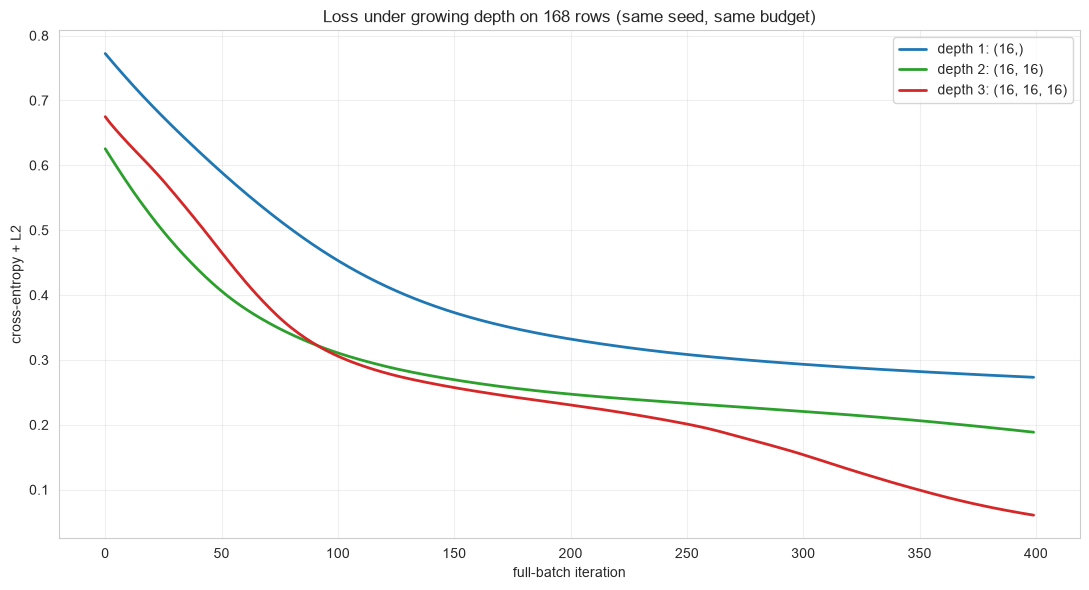

        arch  params  n_iter  final_loss  test_acc
       (16,)      82     400      0.2732    0.8889
    (16, 16)     354     400      0.1886    0.9444
(16, 16, 16)     626     400      0.0607    0.9861

💡 Deeper stacks descend faster early (compositions train momentum quickly), but test
   accuracy does NOT follow on a 240-row problem — depth's payoff needs data volume and/or
   width (§10's digits run 1-layer nets happily; §4's sweep saw accuracy move with rows,
   not layers). More parameters also widen the memorization funnel §3 warned about.


In [10]:
# Depth: same total personality, stacked — does the moons problem need depth?
DEPTHS = [(16,), (16, 16), (16, 16, 16)]
depth_rows = []
plt.figure(figsize=(11, 6))
colors_d = ["#1f77b4", "#2ca02c", "#d62728"]
for (arch_d, color) in zip(DEPTHS, colors_d):
    m_d = MLPClassifierScratch(hidden_layer_sizes=arch_d, activation="relu",
                               max_iter=400, n_iter_no_change=50, random_state=0).fit(X_train_m, y_train_m)
    label_d = str(arch_d)
    plt.plot(m_d.loss_curve_, lw=2, color=color, label=f"depth {len(arch_d)}: {label_d}")
    depth_rows.append({"arch": label_d,
                       "params": sum(W.size + b.size for W, b in zip(m_d.coefs_, m_d.intercepts_)),
                       "n_iter": m_d.n_iter_, "final_loss": m_d.loss_curve_[-1],
                       "test_acc": m_d.score(X_test_m, y_test_m)})
plt.xlabel("full-batch iteration"); plt.ylabel("cross-entropy + L2")
plt.title("Loss under growing depth on 168 rows (same seed, same budget)")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(pd.DataFrame(depth_rows).round(4).to_string(index=False))
print("\n💡 Deeper stacks descend faster early (compositions train momentum quickly), but test")
print("   accuracy does NOT follow on a 240-row problem — depth's payoff needs data volume and/or")
print("   width (§10's digits run 1-layer nets happily; §4's sweep saw accuracy move with rows,")
print("   not layers). More parameters also widen the memorization funnel §3 warned about.")

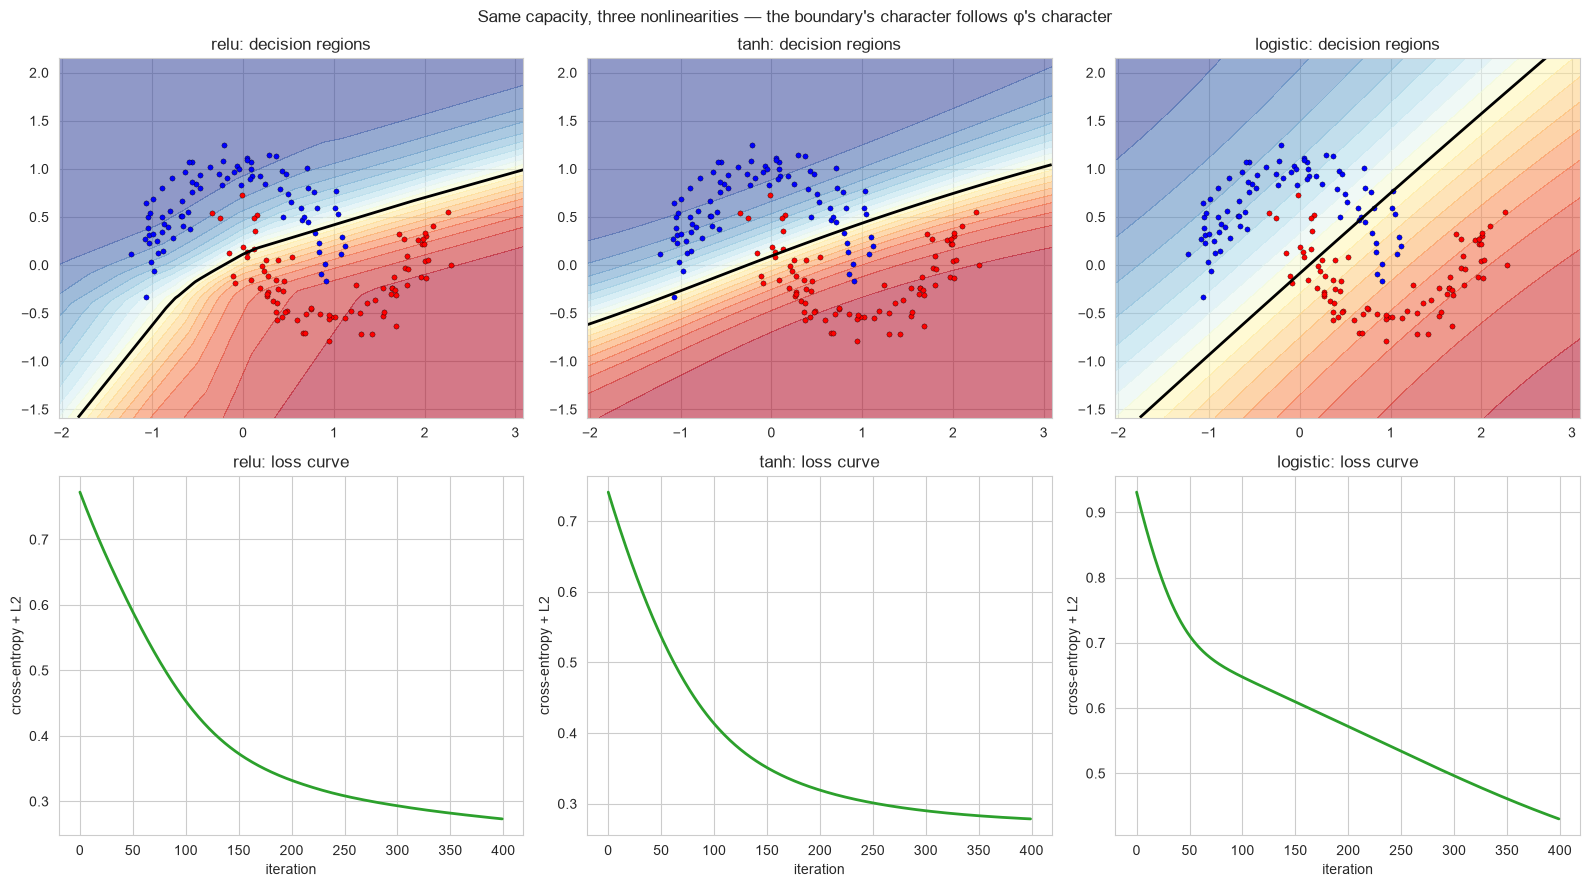

activation  final_loss  test_acc  n_iter
      relu      0.2732    0.8889     400
      tanh      0.2786    0.8750     400
  logistic      0.4303    0.8194     400

💡 relu's hard corners carve sharp region edges (it's also the fastest descender — no
   saturation, gradient always 1 or 0). logistic (sigmoid) smooths every contour: bounded
   output in (0,1) means gentler gradients, e.g. the slowest of the three here. tanh sits
   between: zero-centered like relu-fast, smooth like logistic-gentle.
   Rule of thumb: relu first (cost + speed), tanh when 0-centered targets help, logistic for
   smoothness pressure — and never read too much into act choice on tiny data (§7).


In [11]:
# Activation comparison: relu vs tanh vs logistic — same width, same seed, same budget
ACTS = ("relu", "tanh", "logistic")
act_rows = []
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
pad_a = 0.8
xx_a, yy_a = np.meshgrid(np.linspace(X_m[:, 0].min() - pad_a, X_m[:, 0].max() + pad_a, 250),
                         np.linspace(X_m[:, 1].min() - pad_a, X_m[:, 1].max() + pad_a, 250))

for col_a, act in enumerate(ACTS):
    ax_top, ax_bot = axes[0][col_a], axes[1][col_a]
    m_a = MLPClassifierScratch(hidden_layer_sizes=(16,), activation=act,
                               max_iter=400, n_iter_no_change=50, random_state=0).fit(X_train_m, y_train_m)
    act_rows.append({"activation": act, "final_loss": m_a.loss_curve_[-1],
                     "test_acc": m_a.score(X_test_m, y_test_m), "n_iter": m_a.n_iter_})
    Z_a = m_a.predict_proba(np.c_[xx_a.ravel(), yy_a.ravel()])[:, 1].reshape(xx_a.shape)
    ax_top.contourf(xx_a, yy_a, Z_a, levels=20, cmap="RdYlBu_r", alpha=0.55)
    ax_top.contour(xx_a, yy_a, Z_a, levels=[0.5], colors="black", linewidths=2)
    ax_top.scatter(X_train_m[y_train_m == 0, 0], X_train_m[y_train_m == 0, 1],
                   c="blue", s=14, edgecolors="k", lw=0.25)
    ax_top.scatter(X_train_m[y_train_m == 1, 0], X_train_m[y_train_m == 1, 1],
                   c="red", s=14, edgecolors="k", lw=0.25)
    ax_top.set_title(f"{act}: decision regions")
    ax_bot.plot(m_a.loss_curve_, color="#2ca02c", lw=2)
    ax_bot.set_title(f"{act}: loss curve")
    ax_bot.set_xlabel("iteration"); ax_bot.set_ylabel("cross-entropy + L2")

plt.suptitle("Same capacity, three nonlinearities — the boundary's character follows φ's character", fontsize=12)
plt.tight_layout()
plt.show()

print(pd.DataFrame(act_rows).round(4).to_string(index=False))
print("\n💡 relu's hard corners carve sharp region edges (it's also the fastest descender — no")
print("   saturation, gradient always 1 or 0). logistic (sigmoid) smooths every contour: bounded")
print("   output in (0,1) means gentler gradients, e.g. the slowest of the three here. tanh sits")
print("   between: zero-centered like relu-fast, smooth like logistic-gentle.")
print("   Rule of thumb: relu first (cost + speed), tanh when 0-centered targets help, logistic for")
print("   smoothness pressure — and never read too much into act choice on tiny data (§7).")

ALPHA (L2) SWEEP — the twin adds α·Σ‖W‖² directly (no 1/n; §6 aligns sklearn)
 alpha  weight_sq_norm  test_acc  final_loss
0.0000         13.4395    0.8889      0.2716
0.0000         13.4338    0.8889      0.2718
0.0001         13.3746    0.8889      0.2732
0.0010         12.7689    0.8889      0.2862
0.0100          8.0114    0.8611      0.3756
0.1000          2.0030    0.8194      0.6492
1.0000          0.6679    0.8194      1.3360


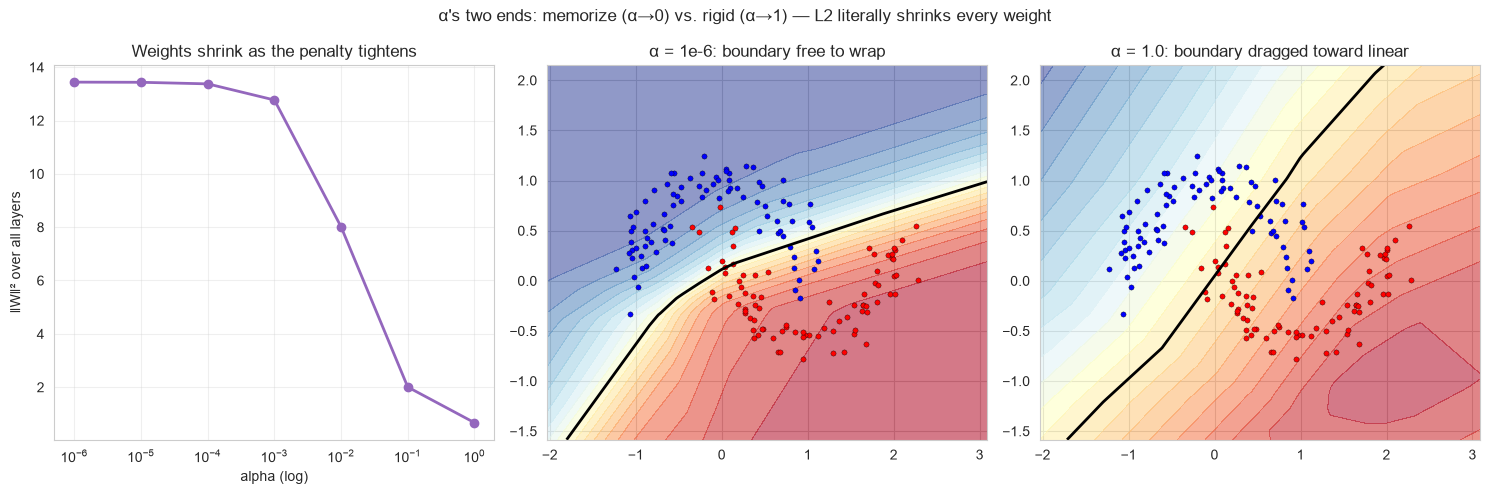

💡 As α grows the total ‖W‖² collapses (the left panel is the arithmetic: the penalty
   eats every weight), and the 0.5-contour concedes its curls — at α=1 the net can barely
   out-bend a logistic regression. Two ends of the same parade:
   α→0 memorizes (train acc high, generalization noisy), α→1 rigidifies (train acc drops).
   The sweet spot is a decade-wide band (§7 prices it with CV).


In [12]:
# alpha (L2) sweep: regularization STRAIGHTENS the boundary toward linear as it grows
ALPHAS = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
alpha_rows = []
for al in ALPHAS:
    m_al = MLPClassifierScratch(hidden_layer_sizes=(16,), activation="relu",
                                alpha=al, max_iter=400, n_iter_no_change=50,
                                random_state=0).fit(X_train_m, y_train_m)
    norm_al = sum(float((W**2).sum()) for W in m_al.coefs_)
    alpha_rows.append({"alpha": al, "weight_sq_norm": norm_al,
                       "test_acc": m_al.score(X_test_m, y_test_m),
                       "final_loss": m_al.loss_curve_[-1]})

alpha_df = pd.DataFrame(alpha_rows)
print("=" * 62)
print("ALPHA (L2) SWEEP — the twin adds α·Σ‖W‖² directly (no 1/n; §6 aligns sklearn)")
print("=" * 62)
print(alpha_df.round(4).to_string(index=False))

fig = plt.figure(figsize=(15, 5))
ax1 = fig.add_subplot(1, 3, 1)
ax1.semilogx(alpha_df["alpha"], alpha_df["weight_sq_norm"], "o-", lw=2, color="#9467bd")
ax1.set_xlabel("alpha (log)"); ax1.set_ylabel("‖W‖² over all layers")
ax1.set_title("Weights shrink as the penalty tightens")
ax1.grid(True, alpha=0.3)

for ax_pair, (al_sel, title_sel) in zip(
        [fig.add_subplot(1, 3, 2), fig.add_subplot(1, 3, 3)],
        [(1e-6, "α = 1e-6: boundary free to wrap"),
         (1.0, "α = 1.0: boundary dragged toward linear")]):
    m_sel = MLPClassifierScratch(hidden_layer_sizes=(16,), activation="relu",
                                 alpha=al_sel, max_iter=400, n_iter_no_change=50,
                                 random_state=0).fit(X_train_m, y_train_m)
    Z_sel = m_sel.predict_proba(np.c_[xx_a.ravel(), yy_a.ravel()])[:, 1].reshape(xx_a.shape)
    ax_pair.contourf(xx_a, yy_a, Z_sel, levels=20, cmap="RdYlBu_r", alpha=0.55)
    ax_pair.contour(xx_a, yy_a, Z_sel, levels=[0.5], colors="black", linewidths=2)
    ax_pair.scatter(X_train_m[y_train_m == 0, 0], X_train_m[y_train_m == 0, 1],
                    c="blue", s=14, edgecolors="k", lw=0.25)
    ax_pair.scatter(X_train_m[y_train_m == 1, 0], X_train_m[y_train_m == 1, 1],
                    c="red", s=14, edgecolors="k", lw=0.25)
    ax_pair.set_title(title_sel)

plt.suptitle("α's two ends: memorize (α→0) vs. rigid (α→1) — L2 literally shrinks every weight", fontsize=12)
plt.tight_layout()
plt.show()

print("💡 As α grows the total ‖W‖² collapses (the left panel is the arithmetic: the penalty")
print("   eats every weight), and the 0.5-contour concedes its curls — at α=1 the net can barely")
print("   out-bend a logistic regression. Two ends of the same parade:")
print("   α→0 memorizes (train acc high, generalization noisy), α→1 rigidifies (train acc drops).")
print("   The sweet spot is a decade-wide band (§7 prices it with CV).")

EARLY STOPPING — improvement must EXCEED tol; window = n_iter_no_change
   tol  window  n_iter  final_loss  test_acc
0.0010      10     178      0.0896       1.0
0.0001      10     387      0.0274       1.0
0.0010      30     198      0.0743       1.0
0.0000      10    2000      0.0029       1.0


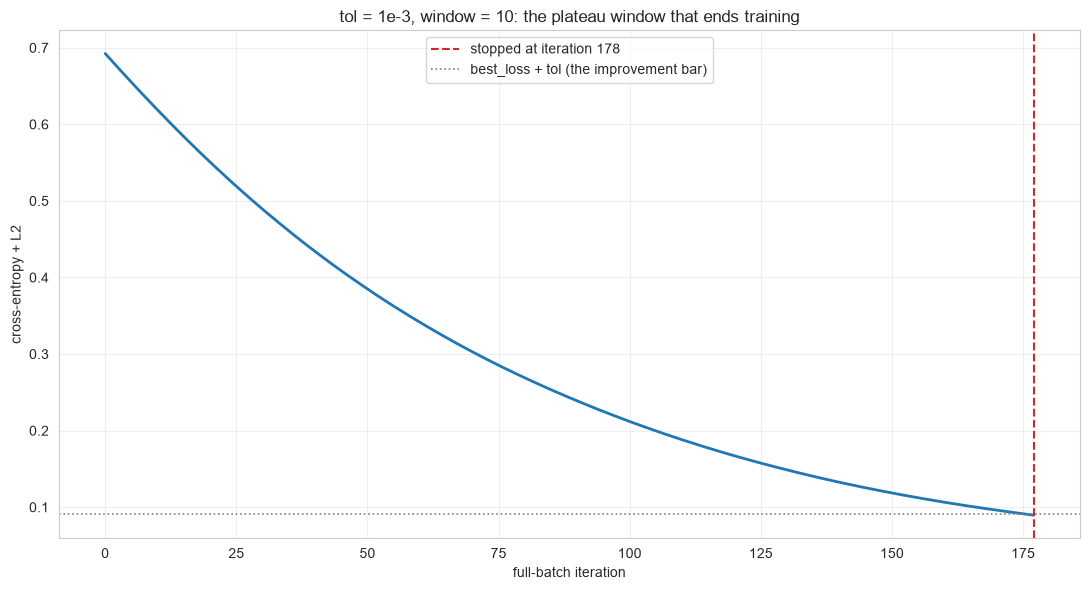

💡 Read the n_iter column left to right: tighter tol (1e-4) and larger window (30) both
   buy *more iterations*, not more learning — the loss hovers cents above its best.
   tol=0.0 never trips the bar and rides to max_iter=2000 as the honest control.
   Boundaries: this is the TRAINING-LOSS protocol; sklearn's early_stopping=True swaps in
   a validation split and reverts to best weights (§6's comparison).


In [13]:
# Early stopping on the training loss: tol + window semantics (fact 6)
X_es, y_es = make_blobs(n_samples=240, centers=2, cluster_std=0.5, random_state=0)
X_tr_es, X_te_es, y_tr_es, y_te_es = train_test_split(X_es, y_es, test_size=0.30, random_state=42)

ES_CONFIGS = [
    {"tol": 1e-3, "window": 10},
    {"tol": 1e-4, "window": 10},
    {"tol": 1e-3, "window": 30},
    {"tol": 0.0, "window": 10},          # never "improves by 0" fails → runs to max_iter
]
es_rows = []
for cfg in ES_CONFIGS:
    m_es = MLPClassifierScratch(hidden_layer_sizes=(16,), activation="relu",
                                max_iter=2000, tol=cfg["tol"],
                                n_iter_no_change=cfg["window"], random_state=0).fit(X_tr_es, y_tr_es)
    es_rows.append({"tol": cfg["tol"], "window": cfg["window"], "n_iter": m_es.n_iter_,
                    "final_loss": m_es.loss_curve_[-1], "test_acc": m_es.score(X_te_es, y_te_es)})

es_df = pd.DataFrame(es_rows)
print("=" * 62)
print("EARLY STOPPING — improvement must EXCEED tol; window = n_iter_no_change")
print("=" * 62)
print(es_df.round(4).to_string(index=False))

plt.figure(figsize=(11, 6))
m_plot_es = MLPClassifierScratch(hidden_layer_sizes=(16,), activation="relu",
                                 max_iter=2000, tol=1e-3, n_iter_no_change=10,
                                 random_state=0).fit(X_tr_es, y_tr_es)
plt.plot(m_plot_es.loss_curve_, color="#1f77b4", lw=2)
plt.axvline(m_plot_es.n_iter_ - 1, color="#d62728", ls="--", lw=1.5,
            label=f"stopped at iteration {m_plot_es.n_iter_}")
plt.axhline(min(m_plot_es.loss_curve_) + 1e-3, color="gray", ls=":", lw=1.2,
            label="best_loss + tol (the improvement bar)")
plt.xlabel("full-batch iteration"); plt.ylabel("cross-entropy + L2")
plt.title("tol = 1e-3, window = 10: the plateau window that ends training")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("💡 Read the n_iter column left to right: tighter tol (1e-4) and larger window (30) both")
print("   buy *more iterations*, not more learning — the loss hovers cents above its best.")
print("   tol=0.0 never trips the bar and rides to max_iter=2000 as the honest control.")
print("   Boundaries: this is the TRAINING-LOSS protocol; sklearn's early_stopping=True swaps in")
print("   a validation split and reverts to best weights (§6's comparison).")

   fit  final_loss  test_acc  heavy_col_Wnorm
   raw      0.6868    0.4750           0.4768
scaled      0.6824    0.5417           0.3449


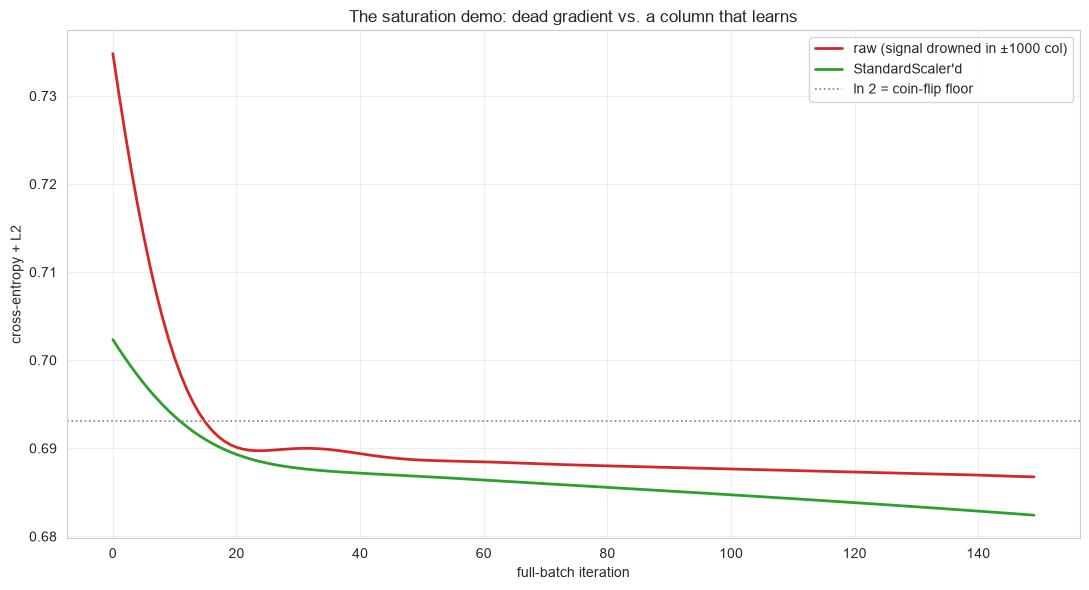

💡 Where §3's table left off: tanh'(±1000) < 1e-13 is dead arithmetic, so the heavy
   column's weights can NEVER move (raw ‖W[:heavy]‖ sits at its ~sqrt(6/(2+16)) Glorot
   size) while the scaled twin's column shoots up as the network leans on it.
   The raw loss curve looks perfectly healthy — improving, smooth — which is EXACTLY why
   this failure hides: loss health ≠ learning progress. Scaling is not etiquette; it is
   the thing that connects φ's derivative to your data (§3 assumption 2, §9 practice 1).


In [14]:
# §3's promised saturation demo — a separating signal hidden in the ripple of a ±1000 column
#   tanh saturates: |z| ≈ 1000 → φ = ±1 exactly and φ' < 1e-13 → the heavy column's gradient is dead
rng_sat = np.random.default_rng(0)
n_sat2 = 400
signal2 = rng_sat.normal(size=n_sat2)
noise2 = rng_sat.normal(size=n_sat2)
heavy2 = 1000.0 * rng_sat.normal(size=n_sat2)
X_sat2 = np.c_[noise2, heavy2 + 0.8 * signal2]
y_sat2 = (signal2 > 0).astype(int)

X_tr_sat2, X_te_sat2, y_tr_sat2, y_te_sat2 = train_test_split(
    X_sat2, y_sat2, test_size=0.30, stratify=y_sat2, random_state=42)
scaler_sat2 = StandardScaler().fit(X_tr_sat2)
X_tr_sat2_s, X_te_sat2_s = scaler_sat2.transform(X_tr_sat2), scaler_sat2.transform(X_te_sat2)

m_sat_raw = MLPClassifierScratch(hidden_layer_sizes=(16,), activation="tanh",
                                 max_iter=150, n_iter_no_change=400, random_state=0).fit(X_tr_sat2, y_tr_sat2)
m_sat_std = MLPClassifierScratch(hidden_layer_sizes=(16,), activation="tanh",
                                 max_iter=150, n_iter_no_change=400, random_state=0).fit(X_tr_sat2_s, y_tr_sat2)

norm_heavy = lambda mm: float(np.linalg.norm(mm.coefs_[0][:, 1]))
sat_rows = [{"fit": "raw", "final_loss": m_sat_raw.loss_curve_[-1],
             "test_acc": m_sat_raw.score(X_te_sat2, y_te_sat2), "heavy_col_Wnorm": norm_heavy(m_sat_raw)},
            {"fit": "scaled", "final_loss": m_sat_std.loss_curve_[-1],
             "test_acc": m_sat_std.score(X_te_sat2_s, y_te_sat2), "heavy_col_Wnorm": norm_heavy(m_sat_std)}]
print(pd.DataFrame(sat_rows).round(4).to_string(index=False))

plt.figure(figsize=(11, 6))
plt.plot(m_sat_raw.loss_curve_, color="#d62728", lw=2, label="raw (signal drowned in ±1000 col)")
plt.plot(m_sat_std.loss_curve_, color="#2ca02c", lw=2, label="StandardScaler'd")
plt.axhline(np.log(2), color="gray", ls=":", lw=1.2, label="ln 2 = coin-flip floor")
plt.xlabel("full-batch iteration"); plt.ylabel("cross-entropy + L2")
plt.title("The saturation demo: dead gradient vs. a column that learns")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("💡 Where §3's table left off: tanh'(±1000) < 1e-13 is dead arithmetic, so the heavy")
print("   column's weights can NEVER move (raw ‖W[:heavy]‖ sits at its ~sqrt(6/(2+16)) Glorot")
print("   size) while the scaled twin's column shoots up as the network leans on it.")
print("   The raw loss curve looks perfectly healthy — improving, smooth — which is EXACTLY why")
print("   this failure hides: loss health ≠ learning progress. Scaling is not etiquette; it is")
print("   the thing that connects φ's derivative to your data (§3 assumption 2, §9 practice 1).")

---

## 6. Implementation with Scikit-learn

Same moons split, now the industry-standard engine: `MLPClassifier` chains the same affine maps through the same activations and, by default, the same **Adam** optimizer. Facts worth pinning before we fit (against sklearn **1.9**, this environment):

- **Defaults match the twin on every shared knob** — `hidden_layer_sizes=(100,)`, `activation='relu'`, `alpha=1e-4`, `learning_rate_init=1e-3`, `max_iter=200`, `tol=1e-4`, `n_iter_no_change=10`. That is deliberate: the twin mirrors sklearn's public surface so "default vs default" is a meaningful fight, and every shared name below behaves as documented in §5
- **sklearn's Adam iterates over shuffled minibatches** — `batch_size='auto'` → `min(200, n_samples)`, reshuffled each epoch; `max_iter` counts *epochs*. On this split (168 training rows) auto-batch = 168 = the whole training set, so a sklearn epoch and a twin full-batch iteration are the same shape *here*; on larger data the paths genuinely diverge (§7's batch demo)
- **Binary vs. multiclass output architecture** — with 2 classes sklearn's output layer is a single sigmoid unit (`out_activation_='logistic'`); the twin always uses the C-column softmax. The meaning of `proba[:, 1]` (P of `classes_[1]`) is identical either way — the twin's column count is just always `len(classes_)`
- **Fitted attributes worth knowing** — `classes_`, `coefs_`/`intercepts_` (same names and shapes as the twin), `loss_`, `loss_curve_` (per-epoch), `n_iter_` (epochs), `t_` (a samples-seen counter), `n_layers_`, `n_outputs_`, `out_activation_` — plus sklearn's full input validation: NaN in → exception at fit, where the twin would run silently and produce `nan` losses (§3's `np.isfinite` ritual covers both)
- **No `class_weight` here either** — the imbalance alternatives of §3 apply unchanged

SCIKIT-LEARN MLP CLASSIFIER — same data, same knobs, same seed
Train/test samples : 168 / 72
Train accuracy     : 88.69%
Test accuracy      : 86.11%
n_iter_            : 500 epochs   (batch_size='auto' → 168 = the whole train split here)
loss_ (final)      : 0.2966   | twin's loss_ : 0.2595
t_ (samples seen)  : 84000
classes_           : [0 1]
n_layers_          : 3  (input + 1 hidden + output)
out_activation_    : logistic  ← a single SIGMOID unit for 2 classes;
the twin always uses the 2-column softmax — same P(class 1), different plumbing


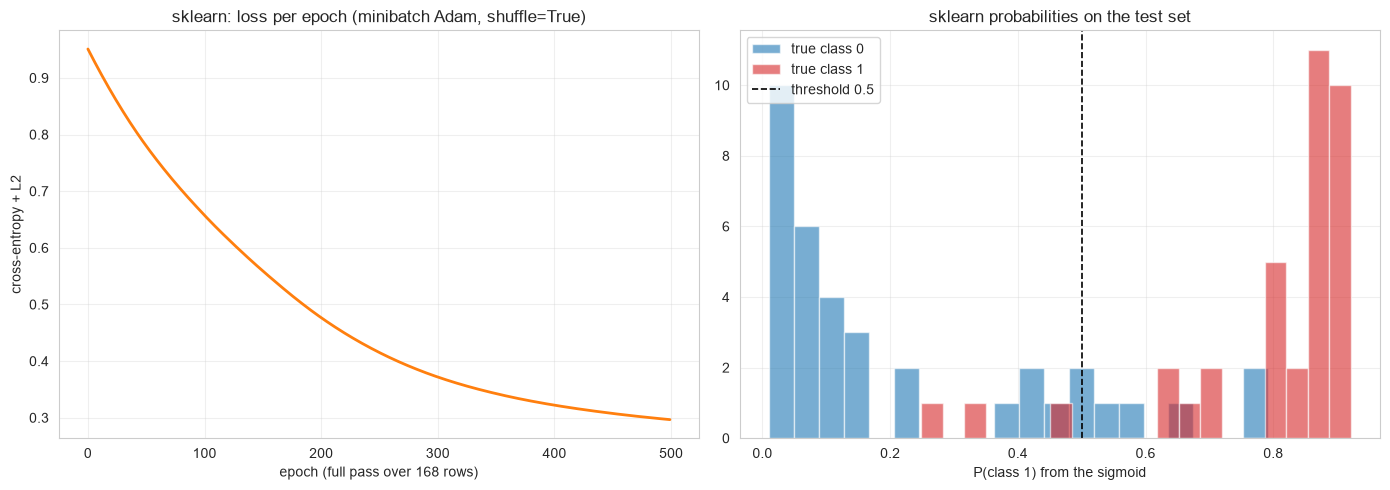

💡 Same story as the twin's §5 figure — loss dives, probabilities separate. A
   ConvergenceWarning at small max_iter is normal here: it is undertraining information,
   not an error (§9's strain-gauge recipe).


In [15]:
# The same §5 moons data, now through sklearn (defaults matched, same seed)
sk_moons = MLPClassifier(
    hidden_layer_sizes=(16,), activation="relu",
    learning_rate_init=1e-3, alpha=1e-4,
    max_iter=500, n_iter_no_change=25, random_state=0,
).fit(X_train_m, y_train_m)

y_pred_sk = sk_moons.predict(X_test_m)
y_proba_sk = sk_moons.predict_proba(X_test_m)

print("=" * 62)
print("SCIKIT-LEARN MLP CLASSIFIER — same data, same knobs, same seed")
print("=" * 62)
print(f"Train/test samples : {X_train_m.shape[0]} / {X_test_m.shape[0]}")
print(f"Train accuracy     : {sk_moons.score(X_train_m, y_train_m):.2%}")
print(f"Test accuracy      : {accuracy_score(y_test_m, y_pred_sk):.2%}")
print(f"n_iter_            : {sk_moons.n_iter_} epochs   (batch_size='auto' → "
      f"{min(200, len(y_train_m))} = the whole train split here)")
print(f"loss_ (final)      : {sk_moons.loss_:.4f}   | twin's loss_ : {model_scratch.loss_:.4f}")
print(f"t_ (samples seen)  : {sk_moons.t_}")
print(f"classes_           : {sk_moons.classes_}")
print(f"n_layers_          : {sk_moons.n_layers_}  (input + 1 hidden + output)")
print(f"out_activation_    : {sk_moons.out_activation_}  ← a single SIGMOID unit for 2 classes;")
print(f"the twin always uses the {len(model_scratch.classes_)}-column softmax — same P(class 1), different plumbing")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(sk_moons.loss_curve_, color="#ff7f0e", lw=2)
axes[0].set_xlabel("epoch (full pass over 168 rows)")
axes[0].set_ylabel("cross-entropy + L2")
axes[0].set_title("sklearn: loss per epoch (minibatch Adam, shuffle=True)")
axes[0].grid(True, alpha=0.3)

axes[1].hist(y_proba_sk[y_test_m == 0, 1], bins=20, alpha=0.6,
             color="#1f77b4", label="true class 0")
axes[1].hist(y_proba_sk[y_test_m == 1, 1], bins=20, alpha=0.6,
             color="#d62728", label="true class 1")
axes[1].axvline(0.5, color="black", ls="--", lw=1.2, label="threshold 0.5")
axes[1].set_xlabel("P(class 1) from the sigmoid")
axes[1].set_title("sklearn probabilities on the test set")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("💡 Same story as the twin's §5 figure — loss dives, probabilities separate. A")
print("   ConvergenceWarning at small max_iter is normal here: it is undertraining information,")
print("   not an error (§9's strain-gauge recipe).")

DUAL ENGINE: SCRATCH vs SCIKIT-LEARN — moons, aligned objective
alpha alignment      : twin 0.0001;  sklearn 0.0168 = alpha_twin × n_train (168)  [sklearn divides L2 by n]
batch shape          : twin full-batch (1 gradient / iteration); sklearn 'auto' → 168 (= full batch here)
fit time             : scratch 0.035s  |  sklearn 0.051s
test accuracy        : scratch 0.8889  |  sklearn 0.8889
final loss           : scratch 0.2935  |  sklearn 0.3730
max |P(class 1) diff|: 0.1959
max |coefs_[0] diff| : 0.547  ← weights do NOT correspond, by design


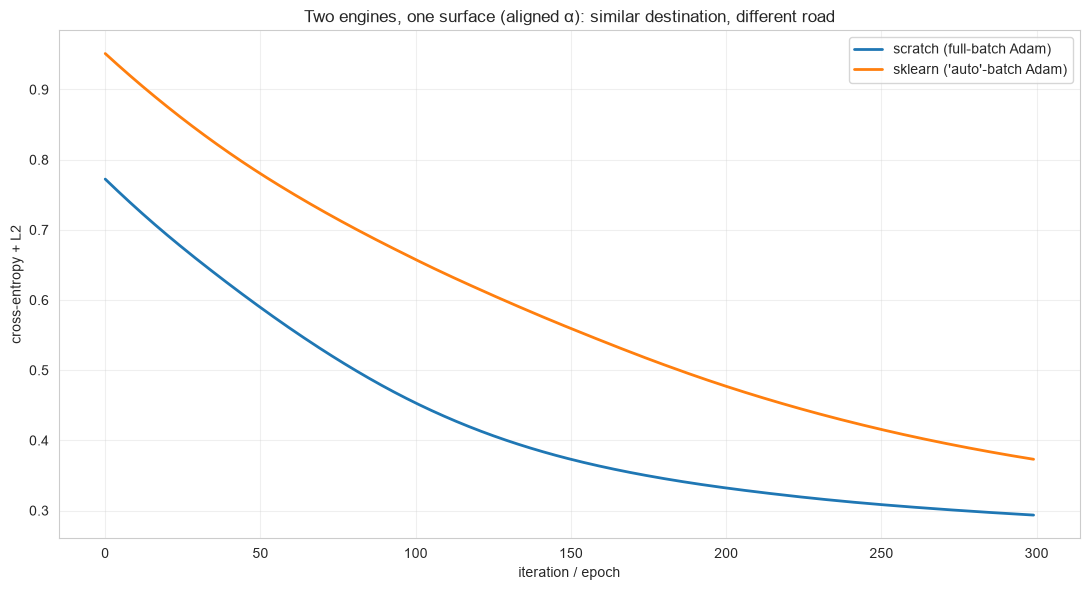

💡 How to read the last two rows — the honest contrast with notebook 02:
   • 02's engines minimized a CONVEX objective with the same optimum → coefficients
     matched to solver tolerance. A one-hidden-layer MLP's loss surface is NOT convex:
     permuting the hidden units is a symmetry of the function, so distinct, equally good
     weights fill the minimizer family — plus init draws differ by design (§5 tour).
   • Therefore 'agreement' here is BEHAVIORAL (accuracy, loss, probabilities in the
     same ballpark), exactly what the twin's test suite asserts — never
     parameter-by-parameter. Same lesson as §11: compare functions, not weights.


In [16]:
# DUAL ENGINE — same objective, aligned alpha, and an honest look at WHERE the engines differ
#   sklearn divides its L2 term by n (§5 fact 4) → align by passing alpha_sk = alpha_twin · n_train
alpha_twin = 1e-4
n_train_align = len(y_train_m)
alpha_sklearn = alpha_twin * n_train_align

t0 = time.time()
m_scratch_d = MLPClassifierScratch(hidden_layer_sizes=(16,), activation="relu",
                                   alpha=alpha_twin, max_iter=300, n_iter_no_change=1000,
                                   random_state=0).fit(X_train_m, y_train_m)
t_scratch_d = time.time() - t0

t0 = time.time()
m_sk_d = MLPClassifier(hidden_layer_sizes=(16,), activation="relu",
                       alpha=alpha_sklearn, max_iter=300, n_iter_no_change=1000,
                       random_state=0).fit(X_train_m, y_train_m)
t_sk_d = time.time() - t0

p_scratch_d = m_scratch_d.predict_proba(X_test_m)[:, 1]
p_sk_d = m_sk_d.predict_proba(X_test_m)[:, 1]

print("=" * 62)
print("DUAL ENGINE: SCRATCH vs SCIKIT-LEARN — moons, aligned objective")
print("=" * 62)
print(f"alpha alignment      : twin {alpha_twin:g};  sklearn {alpha_sklearn:g} "
      f"= alpha_twin × n_train ({n_train_align})  [sklearn divides L2 by n]")
print(f"batch shape          : twin full-batch (1 gradient / iteration); sklearn 'auto' → "
      f"{min(200, n_train_align)} (= full batch here)")
print(f"fit time             : scratch {t_scratch_d:.3f}s  |  sklearn {t_sk_d:.3f}s")
print(f"test accuracy        : scratch {m_scratch_d.score(X_test_m, y_test_m):.4f}  |  "
      f"sklearn {m_sk_d.score(X_test_m, y_test_m):.4f}")
print(f"final loss           : scratch {m_scratch_d.loss_curve_[-1]:.4f}  |  "
      f"sklearn {m_sk_d.loss_curve_[-1]:.4f}")
print(f"max |P(class 1) diff|: {np.abs(p_scratch_d - p_sk_d).max():.4f}")
print(f"max |coefs_[0] diff| : {np.abs(m_scratch_d.coefs_[0] - m_sk_d.coefs_[0]).max():.3f}  "
      f"← weights do NOT correspond, by design")

fig, ax_d = plt.subplots(figsize=(11, 6))
ax_d.plot(m_scratch_d.loss_curve_, color="#1f77b4", lw=2, label="scratch (full-batch Adam)")
ax_d.plot(m_sk_d.loss_curve_, color="#ff7f0e", lw=2, label="sklearn ('auto'-batch Adam)")
ax_d.set_xlabel("iteration / epoch"); ax_d.set_ylabel("cross-entropy + L2")
ax_d.set_title("Two engines, one surface (aligned α): similar destination, different road")
ax_d.legend(); ax_d.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("💡 How to read the last two rows — the honest contrast with notebook 02:")
print("   • 02's engines minimized a CONVEX objective with the same optimum → coefficients")
print("     matched to solver tolerance. A one-hidden-layer MLP's loss surface is NOT convex:")
print("     permuting the hidden units is a symmetry of the function, so distinct, equally good")
print("     weights fill the minimizer family — plus init draws differ by design (§5 tour).")
print("   • Therefore 'agreement' here is BEHAVIORAL (accuracy, loss, probabilities in the")
print("     same ballpark), exactly what the twin's test suite asserts — never")
print("     parameter-by-parameter. Same lesson as §11: compare functions, not weights.")

In [17]:
# Solver comparison on a 3-class blobs problem: adam (default) vs sgd vs lbfgs
X_s3, y_s3 = make_blobs(n_samples=400, centers=3, cluster_std=2.0, random_state=42)
X_tr_s3, X_te_s3, y_tr_s3, y_te_s3 = train_test_split(X_s3, y_s3, test_size=0.30, random_state=42)

SOLVERS = {
    "adam (default)": dict(solver="adam", max_iter=1000, random_state=0),
    "sgd (lr 0.01, momentum 0.9)": dict(solver="sgd", learning_rate_init=0.01, momentum=0.9,
                                        max_iter=1000, random_state=0),
    "lbfgs": dict(solver="lbfgs", max_iter=200, random_state=0),
}
solver_rows = []
for name_sv, kwargs_sv in SOLVERS.items():
    t0 = time.time()
    m_sv = MLPClassifier(hidden_layer_sizes=(32,), **kwargs_sv).fit(X_tr_s3, y_tr_s3)
    solver_rows.append({"solver": name_sv.split(" ")[0],
                        "fit_s": round(time.time() - t0, 4),
                        "n_iter_": m_sv.n_iter_, "loss_": m_sv.loss_,
                        "test_acc": accuracy_score(y_te_s3, m_sv.predict(X_te_s3))})

solver_df = pd.DataFrame(solver_rows)
print("=" * 62)
print("SOLVERS IN ONE ARENA (hidden (32,), 3-class blobs, 280 × 3 features)")
print("=" * 62)
print(solver_df.to_string(index=False))

print("\n💡 lbfgs: quasi-Newton on the FULL batch — no learning rate, no batch size, usually the")
print("   strongest small-data choice (quasi-Newton needs no lr and few iterations; here")
print("   'n_iter_' counts lbfgs's own optimizer iterations, not epochs).")
print("   sgd: the raw, most controllable one — lr and momentum ARE the training; great for")
print("   online/streaming mental models, painful as a first-choice knob set.")
print("   adam: the robust default (adaptive per-parameter steps, minibatch noise as free")
print("   regularization) — and the ONLY solver the scratch twin implements (§5 tour).")

SOLVERS IN ONE ARENA (hidden (32,), 3-class blobs, 280 × 3 features)
solver  fit_s  n_iter_    loss_  test_acc
  adam 0.1503      225 0.014784  0.991667
   sgd 0.0267       58 0.010821  0.991667
 lbfgs 0.0067       14 0.000045  0.991667

💡 lbfgs: quasi-Newton on the FULL batch — no learning rate, no batch size, usually the
   strongest small-data choice (quasi-Newton needs no lr and few iterations; here
   'n_iter_' counts lbfgs's own optimizer iterations, not epochs).
   sgd: the raw, most controllable one — lr and momentum ARE the training; great for
   online/streaming mental models, painful as a first-choice knob set.
   adam: the robust default (adaptive per-parameter steps, minibatch noise as free
   regularization) — and the ONLY solver the scratch twin implements (§5 tour).


            protocol  n_iter  best_train_loss  test_acc
early_stopping=False    1140           0.2336    0.9083
 early_stopping=True      27              NaN    0.5000

False: stops on the training-loss plateau; 'best_train_loss' = best_loss_ (its snapshot).
True: splits off 42 of 280 train rows for validation, stops on the
validation-accuracy plateau for 27 tracked epochs
(best validation accuracy = 0.5000), and REVERTS to the
best-validation weight snapshot — NOT the last epoch's weights.


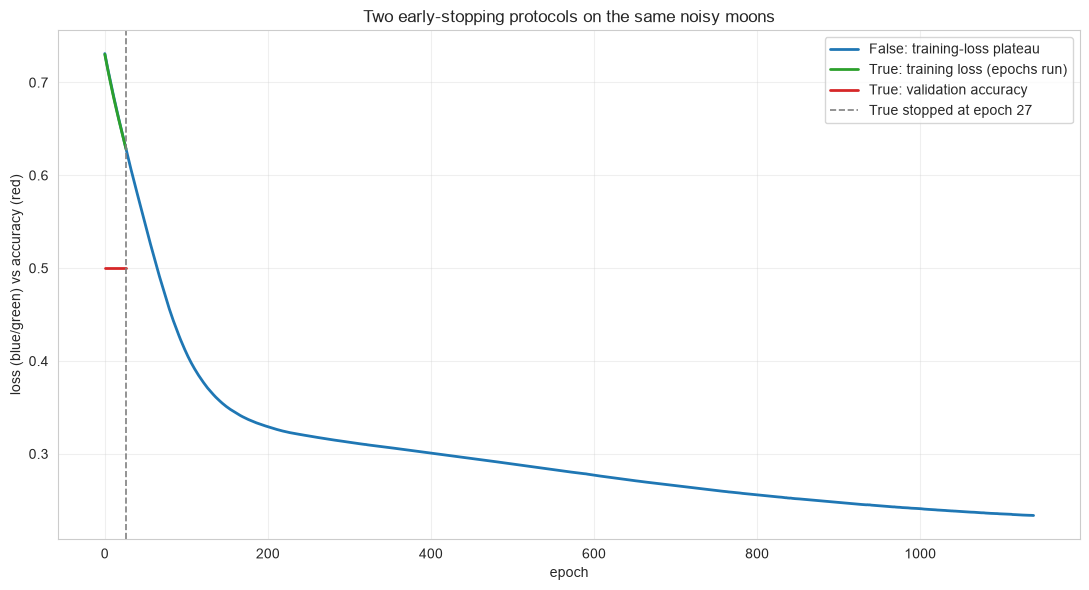

💡 False (also the twin's protocol): stop when the TRAINING loss stops improving by tol
   for n_iter_no_change epochs; keep the final weights. Cheap, no data split, but blind
   to generalization.
   True: carve off validation_fraction of the train rows, stop when their ACCURACY
   plateaus, and revert to the best-validation snapshot — honest-by-construction, at the
   cost of fewer training rows and one more hyperparameter (§8).


In [18]:
# early_stopping semantics: training-loss plateau (False — the twin's protocol)
#                                 vs validation-accuracy plateau with revert-to-best (True)
X_e6, y_e6 = make_moons(n_samples=400, noise=0.30, random_state=0)
X_tr_e6, X_te_e6, y_tr_e6, y_te_e6 = train_test_split(X_e6, y_e6, test_size=0.30, random_state=42)

mlp_stopOff = MLPClassifier(hidden_layer_sizes=(32,), activation="relu", alpha=1e-3,
                            max_iter=2000, n_iter_no_change=25, random_state=0).fit(X_tr_e6, y_tr_e6)
mlp_stopOn = MLPClassifier(hidden_layer_sizes=(32,), activation="relu", alpha=1e-3,
                           max_iter=2000, n_iter_no_change=25,
                           early_stopping=True, validation_fraction=0.15,
                           random_state=0).fit(X_tr_e6, y_tr_e6)

n_val_e6 = round(mlp_stopOn.validation_fraction * len(y_tr_e6))
es6_rows = [
    {"protocol": "early_stopping=False", "n_iter": mlp_stopOff.n_iter_,
     "best_train_loss": mlp_stopOff.best_loss_,
     "test_acc": accuracy_score(y_te_e6, mlp_stopOff.predict(X_te_e6))},
    {"protocol": "early_stopping=True", "n_iter": mlp_stopOn.n_iter_,
     "best_train_loss": None,
     "test_acc": accuracy_score(y_te_e6, mlp_stopOn.predict(X_te_e6))},
]
print(pd.DataFrame(es6_rows).round(4).to_string(index=False))
print(f"\nFalse: stops on the training-loss plateau; 'best_train_loss' = best_loss_ (its snapshot).")
print(f"True: splits off {n_val_e6} of {len(y_tr_e6)} train rows for validation, stops on the")
print(f"validation-accuracy plateau for {len(mlp_stopOn.validation_scores_)} tracked epochs")
print(f"(best validation accuracy = {max(mlp_stopOn.validation_scores_):.4f}), and REVERTS to the")
print("best-validation weight snapshot — NOT the last epoch's weights.")

plt.figure(figsize=(11, 6))
plt.plot(mlp_stopOff.loss_curve_, color="#1f77b4", lw=2, label="False: training-loss plateau")
plt.plot(mlp_stopOn.loss_curve_, color="#2ca02c", lw=2, label="True: training loss (epochs run)")
plt.plot(mlp_stopOn.validation_scores_, color="#d62728", lw=2, label="True: validation accuracy")
plt.axvline(mlp_stopOn.n_iter_ - 1, color="gray", ls="--", lw=1.2,
            label=f"True stopped at epoch {mlp_stopOn.n_iter_}")
plt.xlabel("epoch"); plt.ylabel("loss (blue/green) vs accuracy (red)")
plt.title("Two early-stopping protocols on the same noisy moons")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("💡 False (also the twin's protocol): stop when the TRAINING loss stops improving by tol")
print("   for n_iter_no_change epochs; keep the final weights. Cheap, no data split, but blind")
print("   to generalization.")
print("   True: carve off validation_fraction of the train rows, stop when their ACCURACY")
print("   plateaus, and revert to the best-validation snapshot — honest-by-construction, at the")
print("   cost of fewer training rows and one more hyperparameter (§8).")

                     model  train RMSE
         Linear Regression      0.4642
MLPRegressor (64, 64) tanh      0.0632


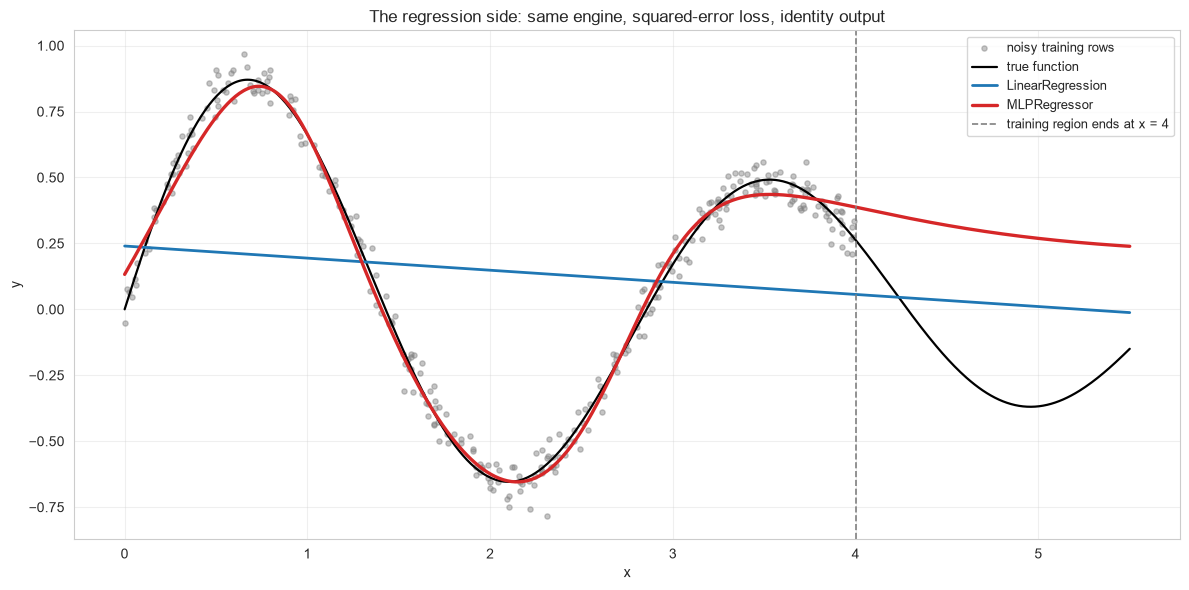

💡 Mechanics note: MLPRegressor is the SAME forward/backward/Adam machinery with a
   squared-error loss and an identity output activation (out_activation_='identity') —
   sklearn-only here because the scratch twin's scope is the classifier (title's scope note).
   Read the tail past the dashed line: the linear model extrapolates its slope; the net
   FLATTENS into whatever its last hidden layer's local level was — a smooth-spline
   property, not a bug. Extrapolation outside the training envelope is always a gamble
   with nets; §8's parameter table is identical machinery for the output layer only.


In [19]:
# The regression twin — sklearn-only (src/models implements the classifier, per scope)
rng_r = np.random.default_rng(0)
n_reg = 320
x_reg = np.sort(rng_r.uniform(0.0, 4.0, n_reg))
y_reg = np.sin(2.2 * x_reg) * np.exp(-0.20 * x_reg) + 0.05 * rng_r.standard_normal(n_reg)
x_grid_r = np.linspace(0.0, 5.5, 500)                       # the unseen [4, 5.5] tail included

models_reg = {
    "Linear Regression": Pipeline([("sc", StandardScaler()),
                                   ("clf", LinearRegression())]),
    "MLPRegressor (64, 64) tanh": Pipeline([("sc", StandardScaler()),
                                            ("clf", MLPRegressor(hidden_layer_sizes=(64, 64),
                                                                 activation="tanh",
                                                                 learning_rate_init=3e-3,
                                                                 max_iter=3000,
                                                                 random_state=42))]),
}
reg_rows = []
for name_r, pipe_r in models_reg.items():
    pipe_r.fit(x_reg.reshape(-1, 1), y_reg)
    y_hat_tr = pipe_r.predict(x_reg.reshape(-1, 1))
    reg_rows.append({"model": name_r,
                     "train RMSE": float(np.sqrt(np.mean((y_reg - y_hat_tr) ** 2)))})
y_mlp_grid = models_reg["MLPRegressor (64, 64) tanh"].predict(x_grid_r.reshape(-1, 1))
y_lin_grid = models_reg["Linear Regression"].predict(x_grid_r.reshape(-1, 1))
print(pd.DataFrame(reg_rows).round(4).to_string(index=False))

plt.figure(figsize=(12, 6))
plt.scatter(x_reg, y_reg, s=14, alpha=0.45, color="gray", label="noisy training rows")
plt.plot(x_grid_r, np.sin(2.2 * x_grid_r) * np.exp(-0.20 * x_grid_r),
         "k-", lw=1.6, label="true function")
plt.plot(x_grid_r, y_lin_grid, color="#1f77b4", lw=2, label="LinearRegression")
plt.plot(x_grid_r, y_mlp_grid, color="#d62728", lw=2.4, label="MLPRegressor")
plt.axvline(4.0, color="gray", ls="--", lw=1.2, label="training region ends at x = 4")
plt.xlabel("x"); plt.ylabel("y")
plt.title("The regression side: same engine, squared-error loss, identity output")
plt.legend(fontsize=9); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("💡 Mechanics note: MLPRegressor is the SAME forward/backward/Adam machinery with a")
print("   squared-error loss and an identity output activation (out_activation_='identity') —")
print("   sklearn-only here because the scratch twin's scope is the classifier (title's scope note).")
print("   Read the tail past the dashed line: the linear model extrapolates its slope; the net")
print("   FLATTENS into whatever its last hidden layer's local level was — a smooth-spline")
print("   property, not a bug. Extrapolation outside the training envelope is always a gamble")
print("   with nets; §8's parameter table is identical machinery for the output layer only.")

---

## 7. Hyperparameter Tuning

The MLP's tuning sheet is shorter than it looks. **Width/depth of `hidden_layer_sizes`** is capacity — the first-order decision; **`alpha`** prices it against generalization (§5's straightening demo); **`max_iter`** is the convergence budget (`ConvergenceWarning` = "budget ran out", §9); **`learning_rate_init`** is usually NOT the first knob under Adam — the per-parameter normalization makes a decade-wide band workable (the sweep below shows where it ends); **`batch_size`, `shuffle`, `early_stopping`** shape the training path rather than the optimum. The three cells put each in hand: a cross-validated capacity × α grid, a learning-rate stress test, and a batch-size comparison.

✨ Best parameters : {'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (64,)}
✨ Best CV accuracy: 0.9642
Test accuracy of the best pipeline: 0.9861

CV accuracy by (width × alpha):
param_mlp__alpha               0.0001  0.0010  0.0100  0.1000
param_mlp__hidden_layer_sizes                                
(2,)                           0.8631  0.8631  0.8631  0.8631
(4,)                           0.8868  0.8868  0.8868  0.8868
(8,)                           0.8988  0.8988  0.8988  0.8988
(16,)                          0.9046  0.9046  0.9046  0.9046
(32,)                          0.9460  0.9460  0.9460  0.9342
(64,)                          0.9642  0.9642  0.9642  0.9583


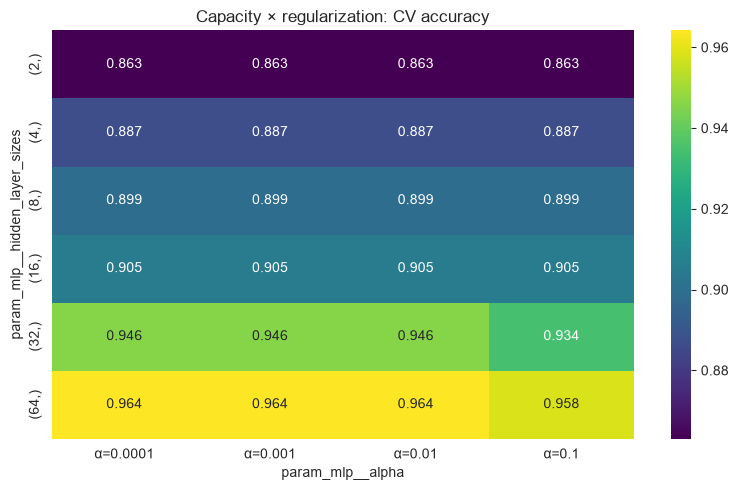

💡 Width owns most of the movement: (2,) caps out badly on these interleaved moons,
   everything from (16,) up sits at the data's ceiling. α matters second — at every
   width the columns wobble by fractions of a point, the α→1 column dragging the daring
   widths down (§5's straightening). Standard practice: pick capacity on CV, then α;
   and keep the scaler INSIDE the pipeline so every fold scales honestly.


In [20]:
# GridSearchCV: capacity (width) × regularization (alpha) on the moons split
param_grid_g = {
    "mlp__hidden_layer_sizes": [(2,), (4,), (8,), (16,), (32,), (64,)],
    "mlp__alpha": [1e-4, 1e-3, 1e-2, 1e-1],
}
grid_g = GridSearchCV(
    Pipeline([("sc", StandardScaler()),
              ("mlp", MLPClassifier(activation="relu", max_iter=1500, random_state=42))]),
    param_grid_g,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy",
).fit(X_train_m, y_train_m)

print(f"✨ Best parameters : {grid_g.best_params_}")
print(f"✨ Best CV accuracy: {grid_g.best_score_:.4f}")
best_g = grid_g.best_estimator_
print(f"Test accuracy of the best pipeline: {accuracy_score(y_test_m, best_g.predict(X_test_m)):.4f}")

pivot_g = pd.DataFrame(grid_g.cv_results_).pivot_table(
    values="mean_test_score", index="param_mlp__hidden_layer_sizes", columns="param_mlp__alpha")
print("\nCV accuracy by (width × alpha):")
print(pivot_g.round(4).to_string())

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_g, annot=True, fmt=".3f", cmap="viridis",
            yticklabels=[str(w) for w in pivot_g.index],
            xticklabels=[f"α={a:g}" for a in pivot_g.columns])
plt.title("Capacity × regularization: CV accuracy")
plt.tight_layout()
plt.show()

print("💡 Width owns most of the movement: (2,) caps out badly on these interleaved moons,")
print("   everything from (16,) up sits at the data's ceiling. α matters second — at every")
print("   width the columns wobble by fractions of a point, the α→1 column dragging the daring")
print("   widths down (§5's straightening). Standard practice: pick capacity on CV, then α;")
print("   and keep the scaler INSIDE the pipeline so every fold scales honestly.")

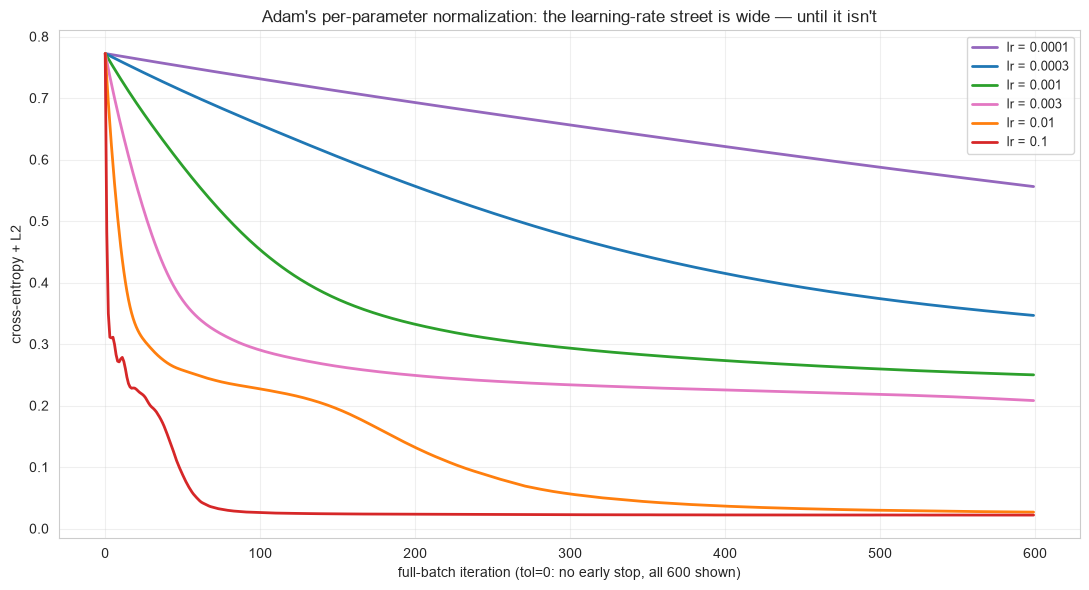

 lr_init  final_loss  test_acc
  0.0001      0.5561    0.8750
  0.0003      0.3465    0.8472
  0.0010      0.2499    0.9306
  0.0030      0.2081    0.9306
  0.0100      0.0267    0.9861
  0.1000      0.0219    0.9861

💡 Typical reading of this plate: 1e-4 descends gently but is still unfinished at 600;
   the 1e-3 … 1e-2 band converges to similar basins (Adam adapts per-parameter, so the
   lr does not need extension-scale babysitting); 1e-1 bounces without settling — a
   step size too large for the surface's curvature to forgive.
   Practical rule: start from the default 1e-3 (twin and sklearn agree), sweep a decade
   around it only if the loss plateaus suspiciously high, and speak in powers of 3.


In [21]:
# learning_rate_init sweep on the TWIN: how wide is Adam's usable street?
LRS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 1e-1]
lr_rows = []
plt.figure(figsize=(11, 6))
colors_lr = ["#9467bd", "#1f77b4", "#2ca02c", "#e377c2", "#ff7f0e", "#d62728"]
for lr_v, color_lr in zip(LRS, colors_lr):
    m_lr = MLPClassifierScratch(hidden_layer_sizes=(16,), activation="relu",
                                learning_rate_init=lr_v, max_iter=600, tol=0.0,
                                n_iter_no_change=600, random_state=0).fit(X_train_m, y_train_m)
    plt.plot(m_lr.loss_curve_, lw=2, color=color_lr, label=f"lr = {lr_v:g}")
    lr_rows.append({"lr_init": lr_v, "final_loss": m_lr.loss_curve_[-1],
                    "test_acc": m_lr.score(X_test_m, y_test_m)})
plt.xlabel("full-batch iteration (tol=0: no early stop, all 600 shown)")
plt.ylabel("cross-entropy + L2")
plt.title("Adam's per-parameter normalization: the learning-rate street is wide — until it isn't")
plt.legend(fontsize=9, loc="upper right"); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(pd.DataFrame(lr_rows).round(4).to_string(index=False))
print("\n💡 Typical reading of this plate: 1e-4 descends gently but is still unfinished at 600;")
print("   the 1e-3 … 1e-2 band converges to similar basins (Adam adapts per-parameter, so the")
print("   lr does not need extension-scale babysitting); 1e-1 bounces without settling — a")
print("   step size too large for the surface's curvature to forgive.")
print("   Practical rule: start from the default 1e-3 (twin and sklearn agree), sweep a decade")
print("   around it only if the loss plateaus suspiciously high, and speak in powers of 3.")

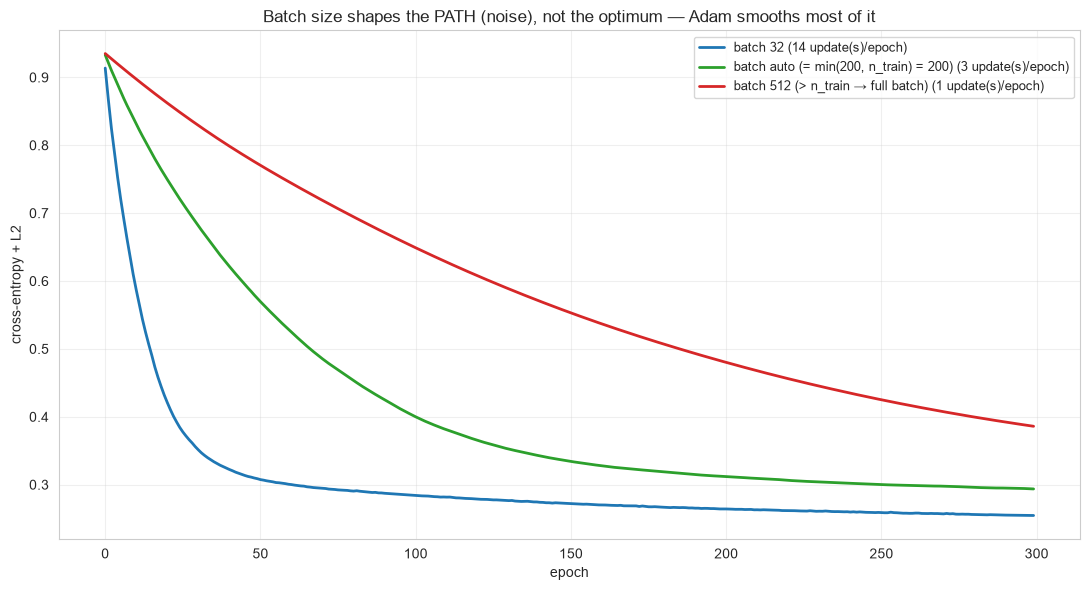

                           batch  updates/epoch  n_iter  final_loss  test_acc
                              32             14     300      0.2545    0.9056
auto (= min(200, n_train) = 200)              3     300      0.2936    0.9000
    512 (> n_train → full batch)              1     300      0.3860    0.8944

train split = 420 rows; sklearn shuffles them afresh every epoch (shuffle=True).

💡 Three regimes in one plot: small batches take more, noisier steps per epoch ('free'
   regularization — usually harmless under Adam); 'auto' = min(200, n) is sklearn's
   middle path; batch ≥ n_train degenerates to EXACTLY the twin's full-batch regime
   (1 update/epoch; same shape as §5's loss curves).
   Note what does NOT change much: the destination. Like the lr sweep, batch size moves
   the road more than arrival — that role belongs to capacity and α (§7's grid).


In [22]:
# batch_size mechanics: more updates/epoch & noisier paths vs. the twin's full-batch regime
X_b32, y_b32 = make_moons(n_samples=600, noise=0.22, random_state=0)
X_tr_b32, X_te_b32, y_tr_b32, y_te_b32 = train_test_split(X_b32, y_b32, test_size=0.30, random_state=42)
n_tr_b32 = len(y_tr_b32)

BATCHES = {
    "32": 32,
    "auto (= min(200, n_train) = 200)": min(200, n_tr_b32),
    "512 (> n_train → full batch)": n_tr_b32,
}
batch_rows = []
plt.figure(figsize=(11, 6))
colors_b = ["#1f77b4", "#2ca02c", "#d62728"]
for (name_b, eff_b), color_b in zip(BATCHES.items(), colors_b):
    m_b = MLPClassifier(hidden_layer_sizes=(16,), activation="relu", batch_size=eff_b,
                        max_iter=300, n_iter_no_change=300, random_state=0).fit(X_tr_b32, y_tr_b32)
    updates_per_epoch = int(np.ceil(n_tr_b32 / eff_b))
    plt.plot(m_b.loss_curve_, lw=2, color=color_b,
             label=f"batch {name_b} ({updates_per_epoch} update(s)/epoch)")
    batch_rows.append({"batch": name_b, "updates/epoch": updates_per_epoch,
                       "n_iter": m_b.n_iter_, "final_loss": m_b.loss_curve_[-1],
                       "test_acc": accuracy_score(y_te_b32, m_b.predict(X_te_b32))})
plt.xlabel("epoch"); plt.ylabel("cross-entropy + L2")
plt.title("Batch size shapes the PATH (noise), not the optimum — Adam smooths most of it")
plt.legend(fontsize=9); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(pd.DataFrame(batch_rows).round(4).to_string(index=False))
print(f"\ntrain split = {n_tr_b32} rows; sklearn shuffles them afresh every epoch (shuffle=True).")
print("\n💡 Three regimes in one plot: small batches take more, noisier steps per epoch ('free'")
print("   regularization — usually harmless under Adam); 'auto' = min(200, n) is sklearn's")
print("   middle path; batch ≥ n_train degenerates to EXACTLY the twin's full-batch regime")
print("   (1 update/epoch; same shape as §5's loss curves).")
print("   Note what does NOT change much: the destination. Like the lr sweep, batch size moves")
print("   the road more than arrival — that role belongs to capacity and α (§7's grid).")

---

## 8. Complete Hyperparameter Reference

### Parameters of `MLPClassifier` / `MLPRegressor` (scikit-learn **1.9**; the scratch twin mirrors the classifier's shared knobs)

#### `hidden_layer_sizes` (tuple of ints, default `(100,)`) **[THE capacity knob]**
- **Description**: one entry per hidden layer, in order — the tuple's length is depth, each entry that layer's width. `(100,)` = one wide hidden layer (the default); `(64, 32)` = two, narrowing
- **Effect**: width bends curves, depth composes features-into-features; both enlarge the parameter count $\sum(\text{fan}_{in}\cdot\text{fan}_{out} + \text{fan}_{out})$ the data must support (§3). On tabular problems the default `(100,)` is often *more* than small data can absorb — start narrow (`(16,)`, `(32,)`) and grow on evidence (§7's grid)
- **Scratch twin**: identical semantics; int (`hidden_layer_sizes=8`) is normalized to the tuple `(8,)` (test-asserted equal)
- **Example**: `MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True)`

#### `activation` (`{'identity', 'logistic', 'tanh', 'relu'}`, default `'relu'`)
- **Description**: the inter-layer nonlinearity. `relu` — cheap, unsaturated on the positive side, hard corners; `tanh` — zero-centered, smooth, saturates both ways; `logistic` — smooth in $(0,1)$, non-zero-centered (slower gradients); `identity` — a no-op that makes the layer linear (§2's collapse — as a hidden activation it deletes capacity; it IS what regressors use at their output layer)
- **Tuning**: rarely the first knob — pick on the data's curvature-scale sensitivity (§5's trio showed the character of each). Dead-ReLU symptoms → try `tanh`
- **Scratch twin**: `relu` / `tanh` / `logistic` (no `identity`); anything else raises `ValueError` at fit
- **Example**: `MLPClassifier(activation='tanh')`

#### `solver` (`{'lbfgs', 'sgd', 'adam'}`, default `'adam'`) **[valid only on scikit-learn — the twin is Adam-only]**
- `lbfgs`: quasi-Newton on the **full batch**; no learning rate, no batch size; usually converges fastest on *small* data (its budget knob is `max_fun`, `n_iter_` counts its own iterations; `tol` is gradient-norm-ish)
- `sgd`: bare stochastic gradient descent — `learning_rate_init`, `momentum`, and the schedule (`learning_rate`, `power_t`) *are* the training; the most controllable, the least forgiving, and scratch-twin-absent
- `adam`: adaptive moments (β1/β2/ε), minibatch reshuffled per epoch by `batch_size`; the robust default and the twin's only optimizer
- **Example**: `MLPClassifier(solver='lbfgs', max_iter=2000)` for a few hundred rows

#### `alpha` (float, default `1e-4` **[THE regularization knob]**) —
- **Description**: L2 penalty on weights (biases exempt). **sklearn adds `alpha·‖W‖² / n_samples` to the per-sample-averaged loss; the twin adds `alpha·‖W‖²` directly** — at equal numbers the twin's penalty is `n_train`× stronger (§5 fact 4). The alignment rule for engine comparisons: `alpha_sklearn = alpha_twin · n_train` (§6's dual-engine cell does exactly this)
- **Effect**: α→0 memorizes (§5: the 1e-6 boundary wraps with slack), α→1 rigidifies (the boundary surrenders its curls toward linear); the useful band is decades wide — log-scale it (§7's grid), and grow α when train/test scores diverge
- **Example**: `MLPClassifier(alpha=0.01)`

#### `batch_size` (int or `'auto'`, default `'auto'` → `min(200, n_samples)`) — sgd/adam only
- More updates per epoch with smaller batches, at noisier-gradients' prices; batch ≥ n degenerates to the twin's exact full-batch one-update-per-epoch regime (§7's demo). Never used by `lbfgs`
- **Example**: `MLPClassifier(batch_size=64)`

#### `learning_rate` (`{'constant', 'invscaling', 'adaptive'}`, default `'constant'`) — **sgd ONLY**
- The schedule that modulates the effective step: `'invscaling'` divides it by `iterations**power_t`; `'adaptive'` lowers it when the loss stalls. **No effect for `adam`** — Adam self-scales per parameter (§2). Classically mixed up: an adam run with `learning_rate='adaptive'` is a silent no-op
- **Scratch twin**: not implemented (Adam only)
- **Example**: `MLPClassifier(solver='sgd', learning_rate='invscaling', power_t=0.25)`

#### `learning_rate_init` (float, default `1e-3`) — sgd & adam only
- The base step size. Under Adam, a decade-wide band around the default works (§7's sweep: `3e-4`‑`1e-2` rails fine; `1e-1` bounces; think in powers of 3). Under sgd it is *the* knob — tune after `momentum`
- **Example**: `MLPClassifier(learning_rate_init=3e-4)`

#### `power_t` (float, default `0.5`) — sgd only
- The inverse-scaling exponent for `'invscaling'`; smaller = slower decay. Irrelevant otherwise
- **Example**: `MLPClassifier(solver='sgd', learning_rate='invscaling', power_t=0.25)`

#### `max_iter` (int, default `200`) —
- For `sgd`/`adam`: maximum **epochs**; for `lbfgs`: maximum **iterations** of its own quadratic model. `ConvergenceWarning` on adam means "budget exhausted" — raise it (this notebook hides warnings but §9 reads them as a strain gauge); typical working levels on tabular data: 500–3000
- **Example**: `MLPClassifier(max_iter=2000)`

#### `shuffle` (bool, default `True`) — sgd/adam only
- Reshuffle the training rows at every epoch. The twin never shuffles — with a fixed seed its full-batch path is *bitwise* deterministic. Turning `shuffle=False` lets minibatch paths become sensitive to row order
- **Example**: `MLPClassifier(shuffle=False)` (rarely what you want; usually a determinism hack)

#### `random_state` (int or None, default `None`) —
- Controls weight **init draws**, the per-epoch **shuffle order**, and (when `early_stopping=True`) the **validation split**. On small data, the seed is part of the experiment (§2's non-convexity note): re-seed comparisons across engines
- **Scratch twin**: one shared `RandomState` draws every Glorot-uniform layer in order — one seed pins the entire trajectory (test-asserted bitwise reproducibility)
- **Example**: `MLPClassifier(random_state=42)`

#### `tol` (float, default `1e-4`) —
- Plateau threshold: with `early_stopping=False`, training stops when the **loss** fails to improve by more than `tol` for `n_iter_no_change` consecutive epochs; with `early_stopping=True`, the same window is judged on the **validation score** instead. The twin mirrors the `False` protocol exactly
- **Example**: `MLPClassifier(tol=1e-3)` for quicker stops on easy problems (§5's table)

#### `verbose` (bool/int, default `False`) —
- Per-epoch progress to stdout with progress bars and per-epoch loss — the first debugging tool when a run "feels wrong" (§9's ECG recipe). The twin's equivalent record is `loss_curve_`
- **Example**: `MLPClassifier(verbose=True)`

#### `warm_start` (bool, default `False`) —
- Reuse the previous fit's weights as the starting point (sklearn reuses the Adam state too) — the building block for manual multi-round training or `partial_fit`-style streaming on `solver='sgd'`. The twin has no counterpart (every `.fit` starts from fresh Glorot draws)
- **Example**: `mlp.fit(X, y); mlp.max_iter += 500; mlp.fit(X, y)` with `warm_start=True`

#### `momentum` (float, default `0.9`) — **sgd only**
- Fraction of the previous update direction added to the current step — sgd's ballast. Irrelevant for adam/lbfgs
- **Example**: `MLPClassifier(solver='sgd', momentum=0.9)`

#### `nesterovs_momentum` (bool, default `True`) — **sgd only**
- Look-ahead correction to momentum (evaluate the gradient after the momentum move). `momentum=0` makes it moot
- **Example**: `MLPClassifier(solver='sgd', momentum=0.95, nesterovs_momentum=True)`

#### `early_stopping` (bool, default `False`) —
- **`False`** (sklearn's default and the twin's protocol): plateau on the **training loss**; keep the final weights
- **`True`**: split off `validation_fraction` of the training rows, watch **validation accuracy** plateau, and **revert to the best-validation weight snapshot** — honest-by-construction, at the cost of fewer training rows (§6's protocol comparison)
- **Example**: `MLPClassifier(early_stopping=True, validation_fraction=0.2)`

#### `validation_fraction` (float, default `0.1`) — with `early_stopping=True`
- The share of training rows carved out for the plateau check (stratified for the classifier). 0.15–0.2 is common on larger data; shrink it when rows are precious
- **Example**: `MLPClassifier(early_stopping=True, validation_fraction=0.15)`

#### `beta_1` / `beta_2` / `epsilon` (floats, defaults `0.9` / `0.999` / `1e-8`) — **adam only**
- Adam's moment decay rates and the numeric floor inside the update (`§2`'s formulas). Leave them alone unless reproducing a paper; the twin hard-codes the same three constants
- **Example**: `MLPClassifier(beta_1=0.9, beta_2=0.999, epsilon=1e-8)` (a no-op restatement of defaults)

#### `n_iter_no_change` (int, default `10`) —
- The plateau window (§5 fact 6): consecutive non-improving epochs before stopping. Tighten for faster stops; widen (or inflate past `max_iter`) when you *want* the full budget's record. The twin implements the identical window on the training loss
- **Example**: `MLPClassifier(n_iter_no_change=25)`

#### `max_fun` (int, default `15000`) — **lbfgs only**
- Maximum loss/gradient *evaluations* per lbfgs run — the budget that actually stops small-data fits; raise together with `max_iter` when lbfgs warns early
- **Example**: `MLPClassifier(solver='lbfgs', max_fun=25000)`

#### Parameters that do NOT exist in the MLP stack — plan around them

| Missing knob | Usual workaround |
|---|---|
| `class_weight` | resample (oversample minority / undersample majority), or shift the decision threshold on `predict_proba` afterward (§9) |
| init selection (no He/Glorot choice) | Glorot-uniform is hard-coded in sklearn and the twin alike; the knob that matters is the seed |
| `partial_fit` for classifiers | train in rounds with `warm_start=True` (or re-fit from scratch — usually fine at these sizes) |
| per-layer lr / layer freezing | not in the classical stack — that is deep-learning-framework territory |

#### Fitted attributes after `.fit` (classifier)
`classes_` (sorted labels — the twin's softmax columns correspond to this order), `coefs_[l]` (fan_in × fan_out weight matrices), `intercepts_[l]` (biases), `loss_` (final training loss), `loss_curve_` (per-epoch/iteration), `best_loss_` (adam/sgd, non-early-stopping), `n_iter_`, `t_`, `n_layers_`, `n_outputs_`, `out_activation_` (`'logistic'` for 2 classes, `'softmax'` beyond, `'identity'` for regressors)

#### The scratch twin's take
```python
from models.neural_network_models import MLPClassifierScratch
MLPClassifierScratch(hidden_layer_sizes=(100,), activation="relu", alpha=1e-4,
                     learning_rate_init=1e-3, max_iter=200, tol=1e-4,
                     n_iter_no_change=10, random_state=None)
```
- exactly sklearn's *adam-path* classifier-facing subset — full-batch instead of minibatch, no shuffling, training-loss early stopping, weights-only L2 without the 1/n (§5's six facts)
- no `class_weight`, no `warm_start`, no `partial_fit`, no solver choice — by design, so the two engines compare behaviorally

### Parameter Combination Recipes

#### Tabular baseline (fit this first):
```python
Pipeline([("sc", StandardScaler()),
          ("mlp", MLPClassifier(hidden_layer_sizes=(64,), max_iter=1000,
                                early_stopping=True, random_state=42))])
```

#### Tiny data (≤ ~1000 rows) — let the quasi-Newton have it:
```python
Pipeline([("sc", StandardScaler()),
          ("mlp", MLPClassifier(solver="lbfgs", hidden_layer_sizes=(32,),
                                max_iter=5000, random_state=42))])
```

#### Capacity × regularization grid (the §7 workflow):
```python
param_grid = {"mlp__hidden_layer_sizes": [(8,), (16,), (32,), (64,)],
              "mlp__alpha": [1e-4, 1e-3, 1e-2, 1e-1]}     # StratifiedKFold + scaler inside the pipeline
```

#### Chasing a deep architecture (when rows and α can afford it):
```python
MLPClassifier(hidden_layer_sizes=(256, 128, 64), alpha=1e-4,
              learning_rate_init=1e-3, batch_size=256, max_iter=3000,
              early_stopping=True, validation_fraction=0.15, random_state=42)
```

#### Imbalance without `class_weight` (§9's fuller recipe):
```python
# resample first (oversample the minority class), then
MLPClassifier(hidden_layer_sizes=(64,), max_iter=1500, random_state=42)
# then choose the decision threshold on validation predict_proba — not 0.5 by default
```

#### Reproducible engine comparison (§6's recipe):
```python
alpha_twin, n_train = 1e-4, len(y_train)
alpha_sklearn = alpha_twin * n_train          # sklearn divides L2 by n; the twin does not
```

---

## 9. Practical Tips & Common Pitfalls

### ✅ Best Practices

#### 1. **Scale features inside a Pipeline — never by hand**
The scaler's means/stds must come from training rows only; a hand-scaled frame leaks test statistics into training, and everything downstream inherits the lie.
```python
pipe = Pipeline([("sc", StandardScaler()), ("mlp", MLPClassifier(hidden_layer_sizes=(64,)))]
).fit(X_train, y_train)     # scaling stays inside CV — zero leakage
```

---

#### 2. **Seed everything, once**
`random_state` on the estimator AND the split; the twin's single shared RNG means one seed pins the whole trajectory. Comparisons across engines need *matched* seeds and matched α (§6's alignment rule).
```python
train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
MLPClassifier(..., random_state=42)
```

---

#### 3. **Start narrow, grow on evidence**
The default `(100,)` is a *lot* of network for 500 tabular rows. Start `(16,)`–`(32,)`, watch the train/test gap, then widen or deepen (§7's grid); add data before adding depth.

---

#### 4. **Treat `ConvergenceWarning` as a strain gauge, not an error**
It means the iteration budget ran out. Raise `max_iter` (500–3000 epochs is common tabularly), read `loss_curve_` to confirm the loss is still descending, or consciously loosen `tol`.
```python
mlp.fit(X, y)
if len(mlp.loss_curve_) == mlp.max_iter and mlp.loss_curve_[-3:].std() > 1e-3:
    ...  # still descending: train longer (or warm_start=True and continue)
```

---

#### 5. **Read `loss_curve_` (and `verbose=True` when debugging)**
Flat-loss + bad accuracy → the capacity/quality mismatch of §3; exploding loss → lr/scale problem; NaN → the run has *inf* gradients — check scaling first. The curve is the network's ECG; the printout is its chart recorder.

---

#### 6. **Set `early_stopping=True` when rows are modest**
L2 + validation-revert kill the memorization funnel early — a two-knob regularizer (§6's comparison shows the semantics exactly).
```python
MLPClassifier(early_stopping=True, validation_fraction=0.15, max_iter=3000)
```
(Twin users: mirror it by watching a held-out score yourself — the twin stops on the training-loss plateau only, keeping final weights.)

---

#### 7. **Imbalance: there is no `class_weight` — resample or threshold**
Oversample the minority class (SMOTE-style or plain repetition), undersample the majority, or move the decision threshold on `predict_proba` for the operating point the costs demand (§10 Example 1 reads the resulting calibration; notebook 02's threshold-sweep recipe is the general tool).

---

#### 8. **Compare engines behaviorally, never parametrically**
Non-convexity + different init streams make weight-level comparisons meaningless (§6 proved it numerically). Accuracy / loss / probability agreement within a band is the contract — exactly what the twin's test suite asserts.

---

#### 9. **Budget lbfgs with `max_fun`, adam/sgd with `max_iter`**
lbfgs stops on function evaluations, not epochs — raising `max_iter` alone may not stop the warning; pair them (`max_iter`, `max_fun`).

---

#### 10. **Dead ReLUs are a config smell, not a data smell**
A `(16,)` relu net stuck at loss ≈ ln 2 with most units silent → try `tanh`, lower `alpha`, another seed, or a smaller `learning_rate_init`. §2's φ' panel explains why (a unit stuck below zero outputs 0 → gradient 0 → never awakens).

### ❌ Common Mistakes

#### 1. **Feeding unscaled features (the saturation trap)**
§5's demo: the ±1000-column's weights never move (‖W‖ ≈ init), the loss curve looks *perfectly healthy*, and accuracy is a coin flip. Symptom: "the net converges and just doesn't care". Cure: `StandardScaler` in the pipeline; verify with `X_train.describe().loc[["mean", "std"]]`.

#### 2. **Capacity hoarding on small data**
`(100,)` on 168 rows = 5,102 parameters chasing 168 labels → train acc → 100%, test wobbles to the base rate. Cure: narrower nets, higher α, more rows, or admit boosting wins this regime (§11).

#### 3. **Speaking SGD's lr language to Adam**
lr 0.1–0.5 folklore wrecks Adam runs (§7's 1e-1 leaf of the sweep). Under Adam the units are different: start at 1e-3 and think in powers of 3.

#### 4. **Reading `coefs_` as feature importances**
First-layer weights are *projections into a learned basis*; nothing in them is a per-feature contribution ranking. Use permutation importance (or SHAP) on the *fitted model*, not the raw matrices.

#### 5. **Forgetting that `max_iter` is an epoch budget under adam/sgd**
A 200-epoch default on a 3-layer net can warn *long before* the loss flattens; interpretations of "the model doesn't learn" off a truncated fit are meaningless.

#### 6. **Trusting saturated probabilities**
A lightly regularized net on small/imbalanced data can push `predict_proba` toward 0/1. If the numbers are consumed (pricing, triage), spot-check calibration (§10 Example 1's Brier readout; notebook 02's `CalibratedClassifierCV` procedure is the deeper treatment).

#### 7. **Comparing engines (or papers) across seeds and alphas**
Different seed → different basin → different accuracy band on small data; different α scale → different objective entirely (the §6 n-scaling). Pin both before calling anything "better".

### Debugging Recipes

#### Loss goes NaN / inf?
1. check scaling first (`StandardScaler` inside the pipeline)
2. drop `learning_rate_init` by ×10 until the curve is finite
3. verify `np.isfinite(X).all()` — one NaN poisons silently (twin) or raises loudly (sklearn — prefer loud)

#### Training fine, test bad? (memorization)
1. raise `alpha` a decade
2. narrow/deepen less: `hidden_layer_sizes` down a rung
3. `early_stopping=True` (+ `validation_fraction`)
4. add rows — capacity converts data, not wishes

#### Both scores low? (underfitting)
1. widen/depth up one rung at a time
2. raise `max_iter` (adam: epochs) and check `loss_curve_` still descending
3. verify scaling (a saturated column caps the ceiling — §5's demo)
4. try `tanh` if ReLUs look dead (§9 practice 10)

#### Loss plateaus high on a *new* problem?
1. check feature scales/constraints (one giant column steals the plane)
2. sweep `learning_rate_init` a decade up/down (§7)
3. re-seed 3× — small-data landscapes differ by basin; a seed lottery is cheap insurance

#### Accuracy great, business says "useless"? (imbalance)
1. report per-class precision/recall — accuracy lies (notebook 02's §4 recipe)
2. resample minority rows, refit
3. move the threshold on `predict_proba` to the cost-optimal operating point

---

## 10. Real-world Examples

Two bundled, offline-deterministic sklearn datasets — a **probability-quality** endgame on real tabular features and a **multiclass** endgame on flattened pixel features:

- **Example 1 — Breast Cancer (569 tumors × 30 numeric features)**: a small-data, probability-consuming regime. Workflow: stratified split → `Pipeline(StandardScaler → MLP)` → metrics vs. a logistic baseline and a random forest → confusion matrix + ROC → **Brier/Brier-style calibration readout** (notebook 02's `CalibratedClassifierCV` material is the deeper repair; here we *measure* probability quality)
- **Example 2 — Digits (1,797 samples × 64 pixel features, 10 classes)**: the multiclass reason softmax exists. Workflow: scaled `(64,)` net → ~97% accuracy → confusion matrix → misclassified-digit gallery → confidence-gate readout

Both run from `sklearn.datasets` — no downloads, fixed seeds throughout.

In [23]:
# Example 1 — breast cancer: 569 tumors × 30 numeric features (target 0 = malignant, 1 = benign)
bc = load_breast_cancer()
X_bc, y_bc = bc.data, bc.target
X_tr_b, X_te_b, y_tr_b, y_te_b = train_test_split(X_bc, y_bc, test_size=0.25,
                                                  stratify=y_bc, random_state=42)
counts_b = np.bincount(y_tr_b)
print("=" * 62)
print("EXAMPLE 1: BREAST CANCER — PROBABILITY QUALITY ON REAL FEATURES")
print("=" * 62)
print(f"Train/test: {len(y_tr_b)} / {len(y_te_b)} tumors × {X_bc.shape[1]} numeric features")
print(f"Train classes: {counts_b[1]} benign, {counts_b[0]} malignant (≈ {counts_b[1]/counts_b[0]:.2f} : 1)")

estimators_b = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=5000, random_state=42))]),
    "MLP (64,)": Pipeline([("sc", StandardScaler()),
                           ("clf", MLPClassifier(hidden_layer_sizes=(64,), activation="relu",
                                                 max_iter=2000, random_state=42))]),
    "Random Forest (300)": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
}
rows_b = []
for name_b, est_b in estimators_b.items():
    est_b.fit(X_tr_b, y_tr_b)
    proba_b = est_b.predict_proba(X_te_b)[:, 1]
    rows_b.append({"Model": name_b,
                   "Accuracy": accuracy_score(y_te_b, est_b.predict(X_te_b)),
                   "ROC-AUC (benign)": roc_auc_score(y_te_b, proba_b),
                   "Brier (benign)": brier_score_loss(y_te_b, proba_b)})
bc_df = pd.DataFrame(rows_b)
print("\n📊 Head-to-head on the held-out test set:")
print(bc_df.round(4).to_string(index=False))
print("\n(label convention: y=1 = benign, so every column reads P(benign) — the class a")
print(" clinician approves or refers on; the same three numbers, one convention.)")

EXAMPLE 1: BREAST CANCER — PROBABILITY QUALITY ON REAL FEATURES
Train/test: 426 / 143 tumors × 30 numeric features
Train classes: 267 benign, 159 malignant (≈ 1.68 : 1)

📊 Head-to-head on the held-out test set:
              Model  Accuracy  ROC-AUC (benign)  Brier (benign)
Logistic Regression     0.986            0.9977          0.0181
          MLP (64,)     0.965            0.9960          0.0196
Random Forest (300)     0.958            0.9949          0.0296

(label convention: y=1 = benign, so every column reads P(benign) — the class a
 clinician approves or refers on; the same three numbers, one convention.)


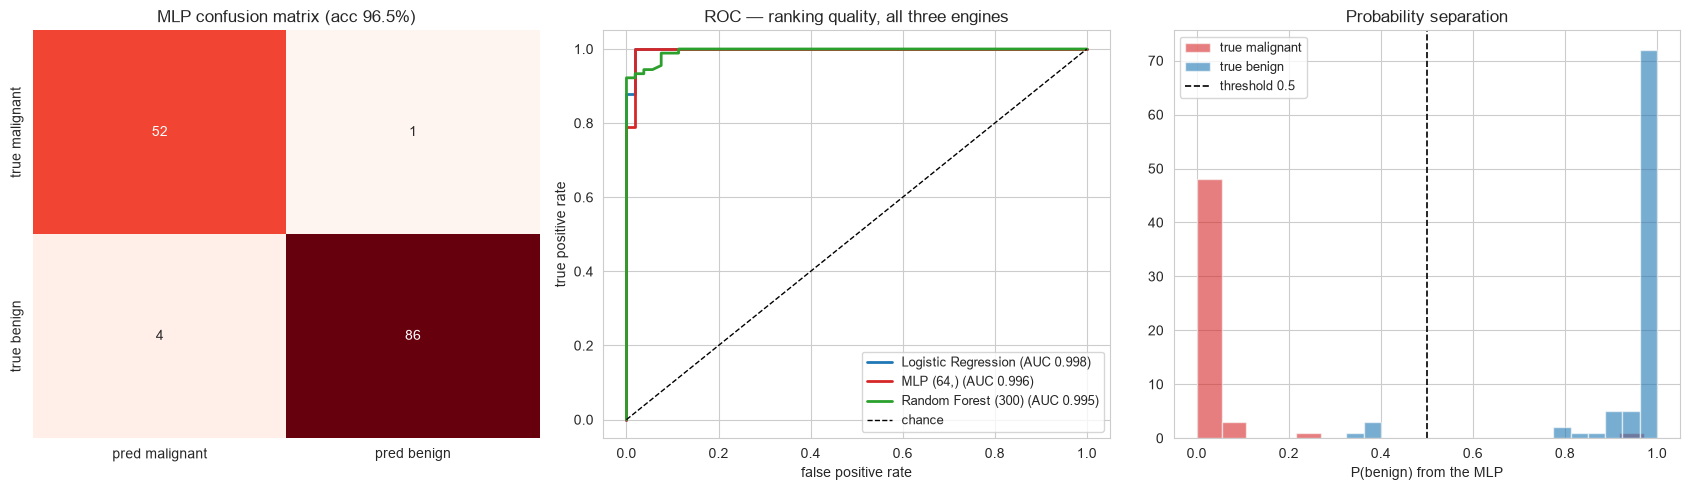

Model                   Accuracy   ROC-AUC    Brier
--------------------------------------------------
Logistic Regression       0.9860    0.9977   0.0181
MLP (64,)                 0.9650    0.9960   0.0196
Random Forest (300)       0.9580    0.9949   0.0296

💡 Read the Brier column once before trusting any of it: the MLP's smooth sigmoid
   output typically lands near the logistic's calibration (a sharp boundary is fine,
   saturated probabilities are not). If the MLP's Brier is clearly worse without an
   obvious cause, repair probabilities with notebook 02's CalibratedClassifierCV recipe
   — accuracy said 'done'; calibration says whether the NUMBERS are priced right.
   And mind the off-diagonal cells (malignant called benign): those handful of rows are
   what a radiologist wants the honest number for — not the accuracy point.


In [24]:
# Example 1 visuals — the MLP's probabilities under the microscope
mlp_b = estimators_b["MLP (64,)"]
proba_mlp_b = mlp_b.predict_proba(X_te_b)[:, 1]
pred_mlp_b = mlp_b.predict(X_te_b)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
cm_b = confusion_matrix(y_te_b, pred_mlp_b)
sns.heatmap(cm_b, annot=True, fmt="d", cmap="Reds", cbar=False, ax=axes[0],
            xticklabels=["pred malignant", "pred benign"],
            yticklabels=["true malignant", "true benign"])
axes[0].set_title(f"MLP confusion matrix (acc {accuracy_score(y_te_b, pred_mlp_b):.1%})")

for (name_b, color_b) in [("Logistic Regression", "#1f77b4"),
                          ("MLP (64,)", "#d62728"),
                          ("Random Forest (300)", "#2ca02c")]:
    proba_c = estimators_b[name_b].predict_proba(X_te_b)[:, 1]
    fpr_b, tpr_b, _ = roc_curve(y_te_b, proba_c)
    axes[1].plot(fpr_b, tpr_b, color=color_b, lw=2,
                 label=f"{name_b} (AUC {roc_auc_score(y_te_b, proba_c):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="chance")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].set_title("ROC — ranking quality, all three engines")
axes[1].legend(fontsize=9)

axes[2].hist(proba_mlp_b[y_te_b == 0], bins=18, alpha=0.6,
             color="#d62728", label="true malignant")
axes[2].hist(proba_mlp_b[y_te_b == 1], bins=18, alpha=0.6,
             color="#1f77b4", label="true benign")
axes[2].axvline(0.5, color="black", ls="--", lw=1.2, label="threshold 0.5")
axes[2].set_xlabel("P(benign) from the MLP"); axes[2].set_title("Probability separation")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

print(f"{'Model':22s} {'Accuracy':>9s} {'ROC-AUC':>9s} {'Brier':>8s}")
print("-" * 50)
for _, row_b in bc_df.iterrows():
    print(f"{row_b['Model']:22s} {row_b['Accuracy']:9.4f} {row_b['ROC-AUC (benign)']:9.4f} "
          f"{row_b['Brier (benign)']:8.4f}")

print("\n💡 Read the Brier column once before trusting any of it: the MLP's smooth sigmoid")
print("   output typically lands near the logistic's calibration (a sharp boundary is fine,")
print("   saturated probabilities are not). If the MLP's Brier is clearly worse without an")
print("   obvious cause, repair probabilities with notebook 02's CalibratedClassifierCV recipe")
print("   — accuracy said 'done'; calibration says whether the NUMBERS are priced right.")
print("   And mind the off-diagonal cells (malignant called benign): those handful of rows are")
print("   what a radiologist wants the honest number for — not the accuracy point.")

In [25]:
# Example 2 — digits: 1,797 samples × 64 pixel features, 10 classes
dg = load_digits()
X_dg, y_dg = dg.data, dg.target
X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(X_dg, y_dg, test_size=0.30,
                                                 stratify=y_dg, random_state=42)
print("=" * 62)
print("EXAMPLE 2: DIGITS — 10 CLASSES THROUGH ONE SOFTMAX (no one-vs-rest)")
print("=" * 62)
print(f"Train/test: {len(y_tr_d)} / {len(y_te_d)} samples × {X_dg.shape[1]} pixel features")
print(f"Class counts (train): {np.bincount(y_tr_d)}  (target_names: 0..9)")

mlp_digits = Pipeline([("sc", StandardScaler()),
                       ("clf", MLPClassifier(hidden_layer_sizes=(64,), activation="relu",
                                             max_iter=1500, random_state=42))]).fit(X_tr_d, y_tr_d)
y_pred_d = mlp_digits.predict(X_te_d)
y_proba_d = mlp_digits.predict_proba(X_te_d)

print(f"\nTest accuracy : {accuracy_score(y_te_d, y_pred_d):.4f}")
print(f"n_iter_ (epochs): {mlp_digits.named_steps['clf'].n_iter_}")
print(f"log_loss      : {log_loss(y_te_d, y_proba_d):.4f}")
print(f"proba shape   : {y_proba_d.shape}  (one softmax column per class 0..9)")
print("\n📋 Classification report:")
print(classification_report(y_te_d, y_pred_d, target_names=[str(c) for c in dg.target_names]))

EXAMPLE 2: DIGITS — 10 CLASSES THROUGH ONE SOFTMAX (no one-vs-rest)
Train/test: 1257 / 540 samples × 64 pixel features
Class counts (train): [124 127 124 128 127 127 127 125 122 126]  (target_names: 0..9)

Test accuracy : 0.9778
n_iter_ (epochs): 174
log_loss      : 0.0924
proba shape   : (540, 10)  (one softmax column per class 0..9)

📋 Classification report:
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        54
           1       0.95      0.98      0.96        55
           2       0.96      1.00      0.98        53
           3       1.00      1.00      1.00        55
           4       0.98      0.96      0.97        54
           5       1.00      0.96      0.98        55
           6       1.00      0.98      0.99        54
           7       0.98      1.00      0.99        54
           8       0.96      0.90      0.93        52
           9       0.96      1.00      0.98        54

    accuracy                           0.

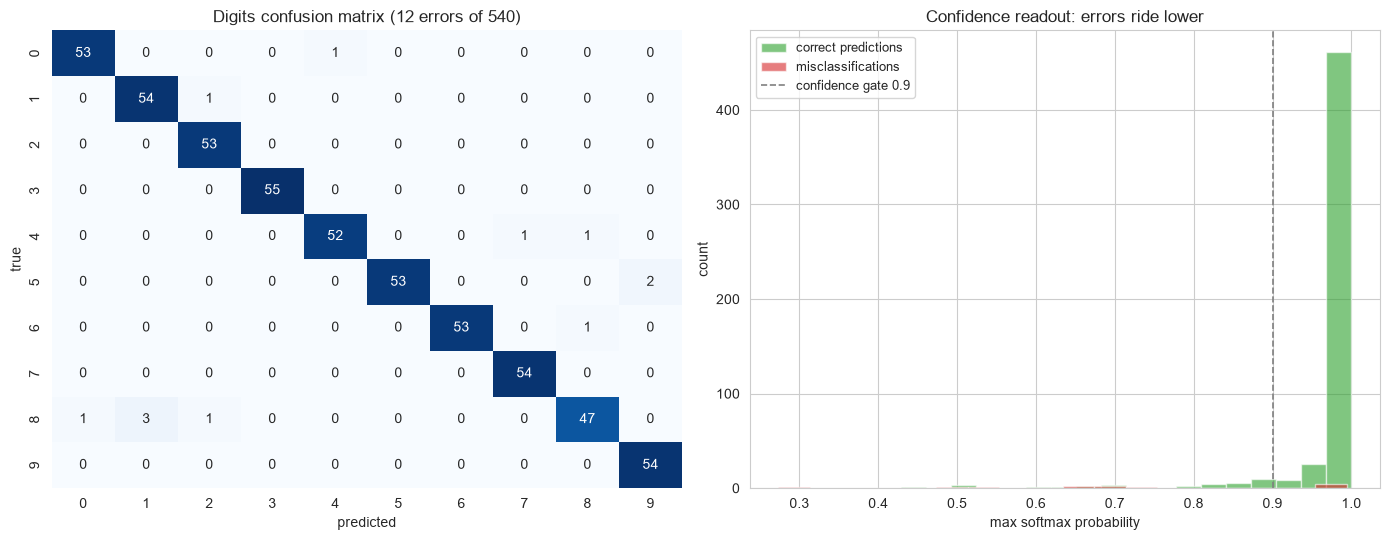

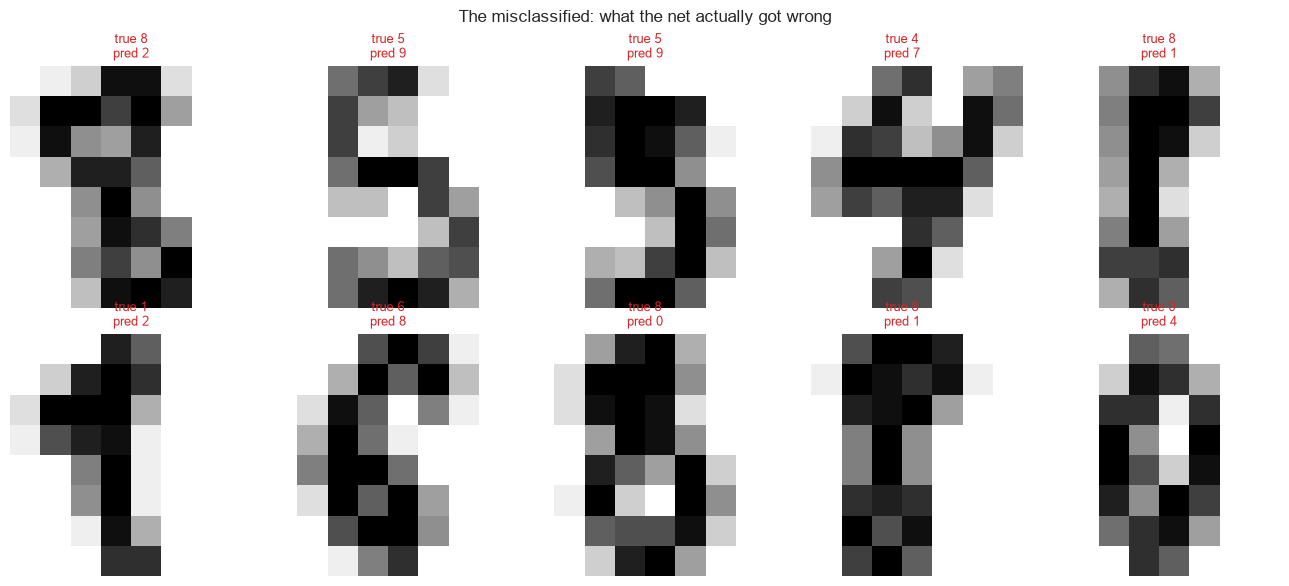

Confidence gate: 500/540 predictions at P ≥ 0.9, 4 of them wrong (→ 0.80% error rate inside the gate vs 2.22% overall)
💡 Typical readouts: most errors cluster at 8↔1/3↔8/9↔5-style lookalikes (the heatmap's
   off-diagonals), and the confidence histogram shows errors riding lower — which is why
   'route anything under 0.9 to human review' is a classic, and cheap, deployment move
   (the threshold-for-deferral business logic notebook 02 §7 formalized for 2 classes).


In [26]:
# Example 2 visuals — confusion matrix, misclassified gallery, and a confidence gate
mis_d = np.where(y_te_d != y_pred_d)[0]
conf_d = y_proba_d.max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
cm_d = confusion_matrix(y_te_d, y_pred_d)
sns.heatmap(cm_d, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true")
axes[0].set_title(f"Digits confusion matrix ({len(mis_d)} errors of {len(y_te_d)})")

axes[1].hist(conf_d[y_te_d == y_pred_d], bins=18, alpha=0.6,
             color="#2ca02c", label="correct predictions")
axes[1].hist(conf_d[mis_d], bins=18, alpha=0.6, color="#d62728", label="misclassifications")
axes[1].axvline(0.9, color="gray", ls="--", lw=1.2, label="confidence gate 0.9")
axes[1].set_xlabel("max softmax probability"); axes[1].set_ylabel("count")
axes[1].set_title("Confidence readout: errors ride lower")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

fig, axes_g = plt.subplots(2, 5, figsize=(13, 6))
for ax_g, j_g in zip(axes_g.ravel(), mis_d[:10]):
    ax_g.imshow(X_te_d[j_g].reshape(8, 8), cmap="gray_r")   # reshape 64 features back to the 8×8 pixel image
    ax_g.set_title(f"true {y_te_d[j_g]}\npred {y_pred_d[j_g]}", fontsize=9,
                   color="#d62728")
    ax_g.axis("off")
plt.suptitle("The misclassified: what the net actually got wrong", fontsize=12)
plt.tight_layout()
plt.show()

n_gate_d = int((conf_d >= 0.9).sum())
n_gate_err_d = int(((conf_d >= 0.9) & (y_te_d != y_pred_d)).sum())
print(f"Confidence gate: {n_gate_d}/{len(y_te_d)} predictions at P ≥ 0.9, "
      f"{n_gate_err_d} of them wrong "
      f"(→ {n_gate_err_d / max(n_gate_d, 1):.2%} error rate inside the gate vs "
      f"{len(mis_d) / len(y_te_d):.2%} overall)")
print("💡 Typical readouts: most errors cluster at 8↔1/3↔8/9↔5-style lookalikes (the heatmap's")
print("   off-diagonals), and the confidence histogram shows errors riding lower — which is why")
print("   'route anything under 0.9 to human review' is a classic, and cheap, deployment move")
print("   (the threshold-for-deferral business logic notebook 02 §7 formalized for 2 classes).")

---

## 11. Comparison with Other Algorithms

### When to Choose the MLP vs. Alternatives

| Aspect | MLP (basics) | Logistic Regression | Decision Tree | Random Forest | Gradient Boosting |
|--------|--------------|---------------------|---------------|---------------|-------------------|
| **Interpretability** | ⭐ (black box) | ⭐⭐⭐⭐⭐ (odds ratios) | ⭐⭐⭐⭐ (visual rules) | ⭐⭐ (importances) | ⭐⭐ |
| **Training speed** | ⭐⭐ (epochs) | ⭐⭐⭐⭐⭐ | ⭐⭐⭐⭐ | ⭐⭐⭐ | ⭐⭐ |
| **Non-linear boundaries** | ⭐⭐⭐⭐⭐ (learned features) | ⭐ (one straight line) | ⭐⭐⭐⭐ (axis-aligned) | ⭐⭐⭐⭐ (axis-aligned) | ⭐⭐⭐⭐ (axis-aligned) |
| **Small-data robustness** | ⭐⭐ | ⭐⭐⭐⭐⭐ | ⭐⭐⭐⭐ | ⭐⭐⭐⭐ | ⭐⭐⭐ |
| **Sample-size appetite** | ⭐⭐⭐⭐ (more is better) | ⭐⭐ | ⭐⭐⭐ | ⭐⭐⭐ | ⭐⭐⭐⭐ |
| **Probability quality** | ⭐⭐⭐⭐ (smooth, check) | ⭐⭐⭐⭐ (calibratable) | ⭐⭐ (jumpy votes) | ⭐⭐⭐ (vote fractions) | ⭐⭐⭐ |
| **Feature scaling needed** | ✅ mandatory | ✅ (for speed) | ❌ | ❌ | ❌ |
| **Imbalance machinery** | ⭐ (no `class_weight`) | ⭐⭐⭐⭐ (`class_weight`) | ⭐⭐⭐ | ⭐⭐⭐⭐ | ⭐⭐⭐⭐ |
| **Multiclass native** | ✅ one softmax | ✅ multinomial | ✅ (one-vs-rest internally) | ✅ | ✅ |
| **Tuning effort vs payoff** | ⭐⭐ (seed-sensitive) | ⭐⭐⭐⭐⭐ | ⭐⭐⭐⭐ | ⭐⭐⭐⭐ | ⭐⭐⭐ |

The MLP's edge is *learned features* — §11's circles demo shows the boundary geometry the whole tree family only patches committee-style. Its costs: a non-convex training lottery, mandatory scaling, and no `class_weight`. Below, the same two-geometry tournament that decides LR versus the tree family in notebooks 02/04 — now including the MLP.

### Practical Comparison

In [27]:
# Head-to-head on TWO geometries: separable blobs vs concentric circles
GEOM_c = {
    "Blobs (separable)": make_blobs(n_samples=600, centers=2, cluster_std=3.0, random_state=42),
    "Circles (concentric)": make_circles(n_samples=600, factor=0.4, noise=0.12, random_state=42),
}
def fresh_estimators_c():
    return {
        "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                         ("clf", LogisticRegression(max_iter=1000))]),
        "MLP (32, 16)": Pipeline([("sc", StandardScaler()),
                                  ("clf", MLPClassifier(hidden_layer_sizes=(32, 16),
                                                        max_iter=2000, random_state=42))]),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    }

rows_c, fitted_c = [], {}
for gname_c, (Xg_c, yg_c) in GEOM_c.items():
    Xtr_c, Xte_c, ytr_c, yte_c = train_test_split(Xg_c, yg_c, test_size=0.30,
                                                  stratify=yg_c, random_state=42)
    for aname_c, est_c in fresh_estimators_c().items():
        t0 = time.time()
        est_c.fit(Xtr_c, ytr_c)
        t_fit_c = time.time() - t0
        acc_c = accuracy_score(yte_c, est_c.predict(Xte_c))
        rows_c.append({"Geometry": gname_c, "Algorithm": aname_c,
                       "Test Accuracy": round(acc_c, 4), "Train Time (s)": round(t_fit_c, 4)})
        fitted_c[(gname_c, aname_c)] = est_c

comparison_c = pd.DataFrame(rows_c)
print("=" * 66)
print("ALGORITHM COMPARISON: TWO GEOMETRIES, FOUR CLASSIFIERS")
print("=" * 66)
print(comparison_c.pivot(index="Algorithm", columns="Geometry",
                         values="Test Accuracy").round(4).to_string())
print("\n💡 On blobs every flexible learner ties at the data's ceiling — and the linear model is")
print("   the *fastest* fit, wasting nothing. On circles the order flips: the MLP's learned")
print("   features wrap the ring directly; the forests patch it committee-style; the line caps")
print("   out at the coin flip. Geometry (and rows) pick the tool — never a leaderboard alone.")

ALGORITHM COMPARISON: TWO GEOMETRIES, FOUR CLASSIFIERS
Geometry             Blobs (separable)  Circles (concentric)
Algorithm                                                   
Gradient Boosting               0.9556                0.9778
Logistic Regression             0.9667                0.4722
MLP (32, 16)                    0.9667                0.9889
Random Forest                   0.9444                0.9833

💡 On blobs every flexible learner ties at the data's ceiling — and the linear model is
   the *fastest* fit, wasting nothing. On circles the order flips: the MLP's learned
   features wrap the ring directly; the forests patch it committee-style; the line caps
   out at the coin flip. Geometry (and rows) pick the tool — never a leaderboard alone.


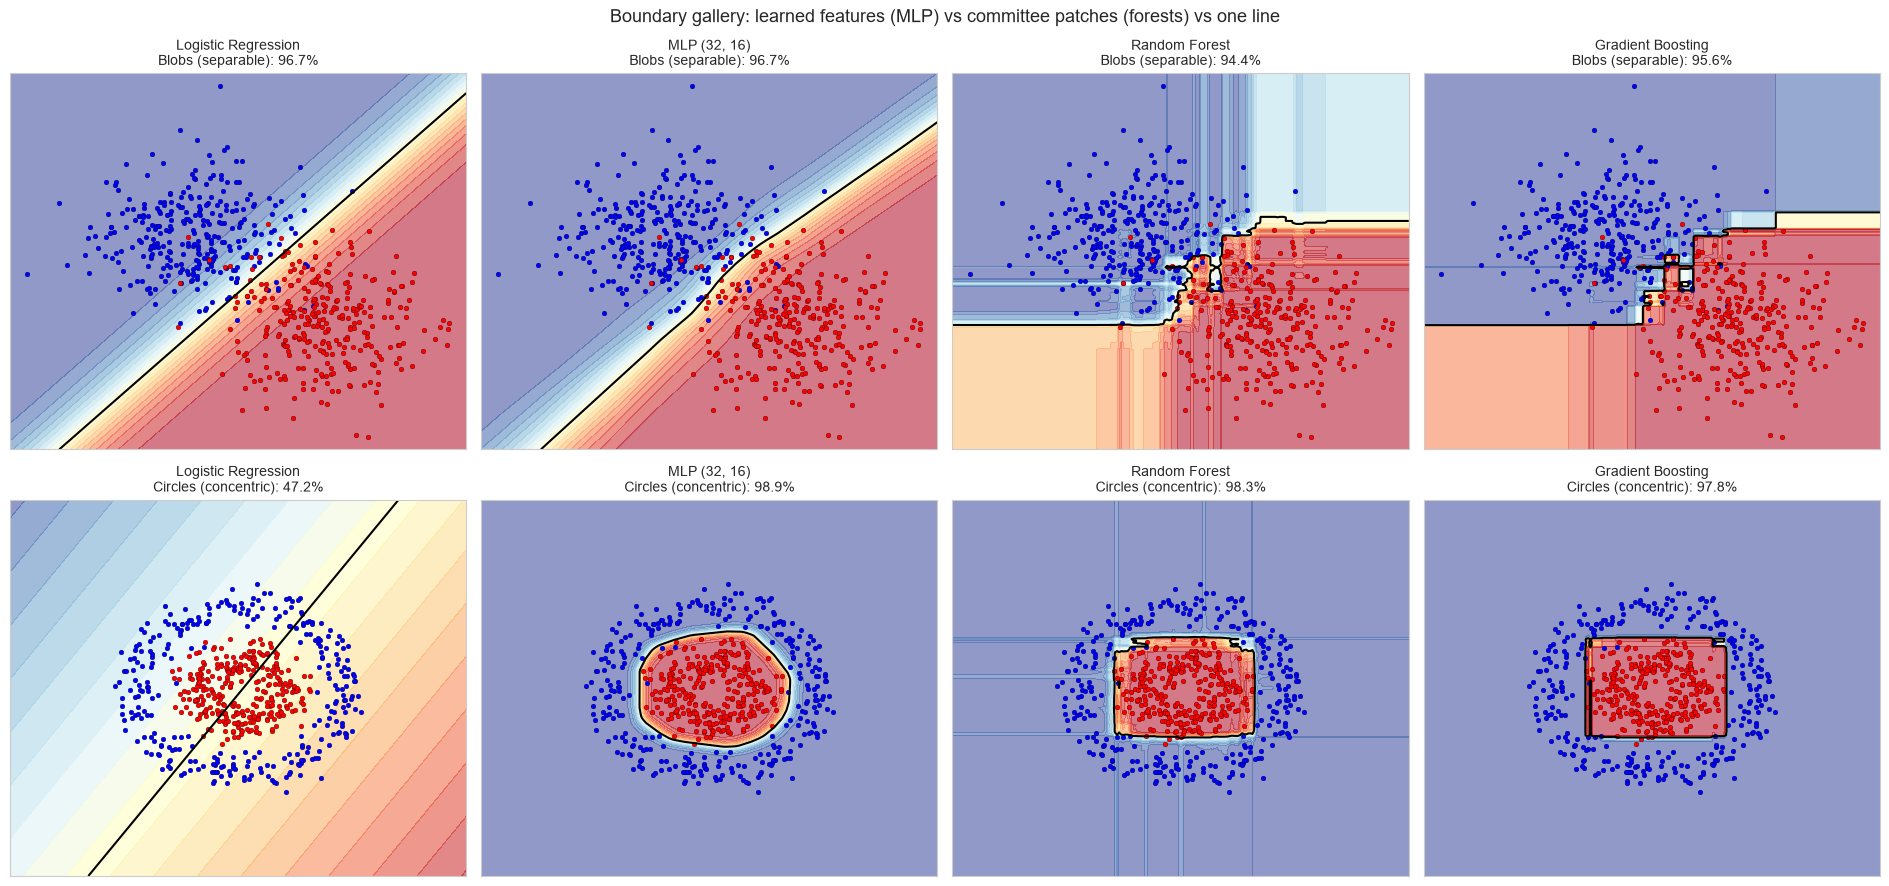

💡 Read the top row first: when a straight wall is the truth, extra flexibility is
   variance to buy and pay for — the MLP's wiggles there cost a hair of accuracy and
   several× fit time. Bottom row: the MLP's boundary follows the *ring*, not the
   grid-square patches the tree committee assembles. Both routes reach the target;
   they pay differently (see §4's data-size sweep and §8's recipes).


In [28]:
# The same eight fits, as boundary pictures: one line vs committee vs learned features
fig, axes_c = plt.subplots(2, 4, figsize=(19, 9))
for row_c, (gname_c, (Xg_c, yg_c)) in enumerate(GEOM_c.items()):
    pad_c = 1.0
    x_min_c, x_max_c = Xg_c[:, 0].min() - pad_c, Xg_c[:, 0].max() + pad_c
    y_min_c, y_max_c = Xg_c[:, 1].min() - pad_c, Xg_c[:, 1].max() + pad_c
    xx_c, yy_c = np.meshgrid(np.linspace(x_min_c, x_max_c, 220),
                             np.linspace(y_min_c, y_max_c, 220))
    for col_c, aname_c in enumerate(fresh_estimators_c().keys()):
        est_c = fitted_c[(gname_c, aname_c)]
        Z_c = est_c.predict_proba(np.c_[xx_c.ravel(), yy_c.ravel()])[:, 1].reshape(xx_c.shape)
        ax_c = axes_c[row_c][col_c]
        ax_c.contourf(xx_c, yy_c, Z_c, levels=20, cmap="RdYlBu_r", alpha=0.55)
        ax_c.contour(xx_c, yy_c, Z_c, levels=[0.5], colors="black", linewidths=1.5)
        ax_c.scatter(Xg_c[yg_c == 0, 0], Xg_c[yg_c == 0, 1], c="blue", s=12, edgecolors="k", lw=0.2)
        ax_c.scatter(Xg_c[yg_c == 1, 0], Xg_c[yg_c == 1, 1], c="red", s=12, edgecolors="k", lw=0.2)
        acc_cell_c = float(comparison_c.loc[(comparison_c["Geometry"] == gname_c)
                                            & (comparison_c["Algorithm"] == aname_c),
                                            "Test Accuracy"].iloc[0])
        ax_c.set_title(f"{aname_c}\n{gname_c}: {acc_cell_c:.1%}", fontsize=10)
        ax_c.set_xticks([]); ax_c.set_yticks([])

plt.suptitle("Boundary gallery: learned features (MLP) vs committee patches (forests) vs one line", fontsize=13)
plt.tight_layout()
plt.show()

print("💡 Read the top row first: when a straight wall is the truth, extra flexibility is")
print("   variance to buy and pay for — the MLP's wiggles there cost a hair of accuracy and")
print("   several× fit time. Bottom row: the MLP's boundary follows the *ring*, not the")
print("   grid-square patches the tree committee assembles. Both routes reach the target;")
print("   they pay differently (see §4's data-size sweep and §8's recipes).")

---

## 12. References

### 📚 Academic Papers & Books

1. **Foundations**:
   - McCulloch, W. S., & Pitts, W. (1943). "A Logical Calculus of the Ideas Immanent in Nervous Activity." *Bulletin of Mathematical Biophysics*, 5(4) — the formal neuron
   - Rosenblatt, F. (1958). "The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain." *Psychological Review*, 65(6) — learnable weights, gradient cornering, and the first wave of optimism
   - Minsky, M., & Papert, S. (1969). *Perceptrons* — the one-layer limits (XOR) whose proof froze the field; §2's collapse demo is the same argument in float64
2. **The Backpropagation Paper** (the recipe this notebook still runs):
   - Rumelhart, D. E., Hinton, G. E., & Williams, R. J. (1986). "Learning Representations by Back-propagating Errors." *Nature*, 323 — §5's guided tour implements exactly its layers
3. **Universal Approximation**:
   - Cybenko, G. (1989). "Approximation by Superpositions of a Sigmoidal Function." *Mathematics of Control, Signals and Systems*, 2
   - Hornik, K., Stinchcombe, M., & White, H. (1989). "Multilayer Feedforward Networks Are Universal Approximators." *Neural Networks*, 2(5)
4. **Initialization & Optimization**:
   - Glorot, X., & Bengio, Y. (2010). "Understanding the Difficulty of Training Deep Feedforward Neural Networks." *AISTATS* — the init family both engines hard-code
   - **Kingma, D. P., & Ba, J. (2014). "Adam: A Method for Stochastic Optimization."** arXiv:1412.6980 — the optimizer both engines default to (§2's m̂/v̂ and §5's `_adam_step`)
   - He, K., et al. (2015). "Delving Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet Classification." *ICCV* — the ReLU-era init alternative (not in sklearn's classical stack; worth knowing)
5. **Books**:
   - Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*, MIT Press (Ch. 6: MLPs; Ch. 8: optimization) — the free reference for everything §2 compressed
   - Nielsen, M. (2015). *Neural Networks and Deep Learning* — the most readable free walkthrough of forward/backward on exactly this notebook's architecture
   - Bishop, C. M. (2006). *Pattern Recognition and Machine Learning* (Ch. 5)
6. **Classical benchmarks**:
   - LeCun, Y., et al. (1998). "Gradient-Based Learning Applied to Document Recognition." *Proceedings of the IEEE*, 86(11) — the digit-recognizing lineage §10 Example 2 samples from

### 🌐 Online Resources

- [scikit-learn MLPClassifier API (1.9)](https://scikit-learn.org/1.9/modules/generated/sklearn.neural_network.MLPClassifier.html) — every parameter here is version-pinned against it
- [Neural Network Models (Supervised) — user guide](https://scikit-learn.org/1.9/modules/neural_networks_supervised.html) — strengths/weaknesses and scaling advice
- [Adam paper](https://arxiv.org/abs/1412.6980) · [Deep Learning book (free)](https://www.deeplearningbook.org/) · [Nielsen's free book](http://neuralnetworksanddeeplearning.com/)
- [3Blue1Brown: Neural Networks series](https://www.3blue1brown.com/topics/neural-networks) — the best-visualized backprop; watch after §5
- [StatQuest: Neural Networks playlist](https://www.youtube.com/@statquest)

### 📊 Key Concepts to Master

- **The nonlinearity is the capacity**: compose affine layers without φ and the net collapses to one affine map (§2 proved it numerically); every hidden unit is one learned feature
- **Forward = activations list; backward = chain rule + φ' via the *stored output*** (the twin never caches pre-activations — §5 fact 1)
- **Softmax + CE cancel to (p − onehot)/n**: the same residual magic as notebook 02's (p − y), one level up (§5 fact 3)
- **L2 on weights only, without the 1/n**: biases exempt; the sklearn-α alignment rule is `alpha_sk = alpha_twin · n_train` (§5 fact 4 → §6's dual engine)
- **Full-batch Adam with bias correction**: m̂/v̂ make the first step already lr-sized; per-parameter normalization is why the lr street is wide (§7's sweep)
- **Early stopping, two protocols**: training-loss plateau keeping final weights (twin, sklearn-False) vs. validation-revert-to-best (sklearn-True) (§6's comparison)
- **Non-convexity**: hidden-unit permutation symmetry + init draws ⇒ compare engines *behaviorally*; seed is part of the experiment (§2, §6)
- **The saturation trap**: |z| ≫ 1 kills φ' and freezes weights — StandardScaler inside a Pipeline is not etiquette, it is the circuit breaker (§3, §5)
- **No `class_weight` in the MLP stack**: resample, undersample, or threshold post-hoc (§9); accuracy lies under imbalance

### 🔗 Related Notebooks in this Repository

- `02_logistic_regression.ipynb` — the one-neuron special case; this notebook's loss, gradient cancellation, and threshold economics all generalize from it
- `03_decision_trees.ipynb` / `04_random_forest.ipynb` — the axis-aligned feature builders (§11's committee boundary)
- `05_support_vector_machines.ipynb` — the kernel alternative to learned features (§2's "fixed feature map" vs. the MLP's learned one)
- `08_gradient_boosting.ipynb` — the tabular rival §4 and §11 defer to below the few-thousand-row line
- `16_ensemble_methods.ipynb` — bagging/boosting/blending: the other way to buy flexibility without a single big model
- `other/ml_vs_llm.md` — where classical nets (and this classical stack) keep beating the modern pipeline

### 📈 Evaluation Metrics for NN Classification

**Balanced data:** accuracy + macro-F1; log loss (the training metric the loss_curve_ tracks)

**Imbalanced data:** per-class precision/recall, PR-AUC; resample, then re-threshold (§9)

**Probability consumers:** Brier score + reliability diagrams (notebook 02's calibration chapter) — the §10 Example 1 readout is the habit, `CalibratedClassifierCV` the repair

**Multiclass:** confusion matrix + per-class report (§10 Example 2) + the max-probability confidence histogram (a deployment-gate view foreign to tree families)

---

## Summary & Key Takeaways

### What We Learned

1. **Theory**: an MLP = chain of affine maps interleaved with pointwise nonlinearities, trained by backpropagation (the chain rule, layer by layer) under Adam on cross-entropy + L2 — and it is literally notebook 02's logistic regression made *stacked*: strip the nonlinearities and the whole architecture collapses to that one neuron (§2 proved it to float64)
2. **The six load-bearing behaviors of the twin**: activations cached without softmax; loss computed in log space (no ε); the (softmax − onehot)/n residual; weights-only L2 without the 1/n mismatch; bias-corrected full-batch Adam; training-loss early stopping keeping final parameters (§5's guided tour)
3. **Assumptions**: trainability over distributional claims — scaled features (§5's saturation demo: a *dead* column's weights sit at init while the loss curve looks perfectly healthy), rows ≥ 10–30× parameters, finite dense matrices, no `class_weight` (resample or threshold)
4. **Non-convexity**: hidden-unit permutation symmetry and init draws mean weights never match across engines — behavioral agreement (accuracy/loss/proba bands) is the honest comparison, and the seed is part of the experiment
5. **Hyperparameters**: width/depth = capacity priced by `alpha`; `max_iter` = epoch budget; `learning_rate_init` is forgiving under Adam (a decade around 1e-3); `batch_size` shapes the path, not the destination; `early_stopping=True` trades rows for generalization honesty (§6's protocol comparison)
6. **Practice**: breast cancer (probability-quality readout — accuracy says "done", the Brier column says whether the numbers deserve pricing) and digits (one softmax, 10 classes, ~97% accuracy, error gallery + confidence gate)
7. **The honest engine lesson**: on a convex objective (02) engines matched coefficients; on this non-convex one they match *behavior* (§6's dual-engine cell made the contrast quantitative)

### When to Use an MLP

✅ **Use when**:
- non-linear class structure over tabular features and thousands of rows (§4's crossover demo)
- a genuine multiclass question with smooth class structure (§10's digits — one softmax, no machinery)
- regression on smooth surfaces (`MLPRegressor`, §6) where linear terms underfit
- the goal is downstream deep learning — every piece of §2/§5 transfers unchanged
- you want the *smoothest* probability surface of the card-based families (§11's table; verify with §10's readout)

❌ **Avoid when**:
- tabular rows < ~1–3k with boosting/forests available — they win the regime with less risk (§4's sweep, §11's table)
- coefficient-level explanations are the deliverable (odds ratios are notebook 02's; hidden units don't translate)
- severe imbalance without a data budget (no `class_weight`; the machinery you must add is §9's resampling/thresholding)
- dream-scale hyperparameter budgets without deep-learning tooling — that is framework territory, not this stack (§8's honest gaps table)

### Best Practices Checklist

- ✅ `StandardScaler` inside a `Pipeline` — the saturation trap's circuit breaker (§5's demo)
- ✅ seed `random_state` on the estimator AND the split; match α scale when comparing engines (`alpha_sk = alpha_twin · n_train`)
- ✅ start `(16,)`–`(32,)`; widen/depth on *evidence* from the train/test gap (§7's grid)
- ✅ read `loss_curve_` as the ECG; `verbose=True` for debugging; treat `ConvergenceWarning` as a budget gauge (§9)
- ✅ `early_stopping=True` + `validation_fraction` when rows are modest
- ✅ GridSearchCV on a *log* α grid with stratified folds; scaler inside the pipeline (§7)
- ✅ evaluate the operating point, not the class: threshold `predict_proba` per costs; calibrate when the numbers are consumed (§10 Ex.1)
- ✅ behavioral twin-vs-sklearn comparisons only — never parameters (§6)

### Critical Requirements

1. **Dense, finite, numeric matrix** — impute/encode first; `np.isfinite(X).all()` before every fit (sklearn raises loudly; the twin dies quietly)
2. **Standardized features** — the highest-leverage preprocessing step in the whole notebook
3. **Rows vs. parameters** — 10–30× minimum; capacity converts data, not wishes (§4's sweep)
4. **Sorted-label conventions** — `classes_` order fixes softmax columns; `10/20` labels behave like `0/1`

### Advantages vs Disadvantages

**Advantages:**
- ✅ learns its own features — the only family here whose boundary is *trained into existence* rather than imposed (§2's φ vs every tree's grid)
- ✅ one softmax, any class count — the multiclass machinery is free (§10 Ex.2)
- ✅ one backward engine from 98 parameters to transformers — the study path *is* the career path
- ✅ smooth, consistent probability surfaces (verify, then price on them — §10 Ex.1)

**Disadvantages:**
- ❌ the training lottery: non-convexity + init draws make seeds matter (§2, §6)
- ❌ mandatory scaling and no `class_weight` (§3, §9)
- ❌ opacity: hidden-unit coefficients are not business language (§9's mistake #4)
- ❌ small-tabular regime belongs to boosting/forests (§4's sweep, §11's table)

### Unique Characteristic: The Network That Manufactures Its Own Features

Trees buy features with thresholds, SVM with kernels, forests by committee — all *imposed* representations. The MLP's hidden layer is **learned**: §2's hand-weighted demo showed four tanh detectors composing into a bent boundary, and §5 replaced the hand with the data (width sweep) — the same mechanism, minimized by a single loss. That license (the nonlinearity between layers) is why the collapse demo matters: it is the difference between "more layers" and "more capacity". Every chart in this notebook is that license measured.

### Next Steps

1. **Re-run §5's demos with three different `random_state`s** — feel the training lottery on a small dataset before it surprises you in a real one
2. **Extend §7's grid to depth** (`(16,16)`, `(32,16)`) and per-width α rows; read the heatmap exactly as §7 taught
3. **Wire the twin into your own tabular problem** — pipeline the scaler, search width × α, and compare against 08's boosting on the same split
4. **Read `08_gradient_boosting.ipynb`** for the tabular rival and `16_ensemble_methods.ipynb` for the committee alternative to single-net capacity
5. **Watch 3Blue1Brown's backprop series** after §5 — the visual intuition will lock the matrix algebra in permanently
6. **Reflect**: hidden unit #1 of your `(16,)` net is a learned feature — what would a stakeholder's question about it look like, and where did the answer live in the data?

---

**Congratulations!** You can now train, diagnose, and honestly compare a neural network — and you know exactly why its capacity must be paid for in data, scaling, and regularization, and why "it's just stacked logistic regressions" is almost right in every sentence. 🎯🎉

**Remember**: without a between-layer nonlinearity the network is a linear model in a trench coat (§2, proved by arithmetic); without standardized features it is a saturated pipe (§5, shown by dead weights); without regularization and rows it is a memorizer (§4's curve). Trainable ≠ generalizable — the license is paid for at every step.